# **Đồ án cuối kì CS116**

# Phân tích dữ liệu và EDA

## Tên bộ dataset
### M5 Forecasting - Accuracy

### Mục tiêu
+ Chúng ta được giao nhiệm vụ dự đoán doanh số bán hàng trong 28 ngày tới dựa trên dữ liệu do tập đoàn bán lẻ khổng lồ Walmart
cung cấp.


### Dữ liệu:
1. Chúng ta đang làm việc với 42.840 chuỗi thời gian phân cấp (hierarchical time series). Dữ liệu được thu thập từ 3 bang của Hoa Kỳ:
California (CA), Texas (TX) và Wisconsin (WI).
2. Từ "phân cấp" ở đây có nghĩa là dữ liệu có thể được tổng hợp ở nhiều cấp độ khác nhau, bao gồm:
+ Cấp độ sản phẩm riêng lẻ (item)
+ Phòng ban (department)
+ Danh mục sản phẩm (category)
+ Cấp độ tiểu bang (state).

3. Thông tin doanh số được ghi nhận từ tháng 1 năm 2011 đến tháng 6 năm 2016.
4. Ngoài các con số về doanh số bán hàng, chúng ta còn được cung cấp thêm dữ liệu liên quan như:
+ Giá bán (sell prices)
+ Chương trình khuyến mãi
+ Ngày nghỉ/lễ.
Lưu ý: Chúng ta được cảnh báo rằng phần lớn các chuỗi thời gian này có rất nhiều giá trị bằng 0
(không có sản phẩm nào được bán vào ngày đó).


## Độ đo đánh giá mô hình

**Độ đo đánh giá mô hình**

Thống nhất sử dụng độ đo RMSE:

\begin{equation}
\text{RMSE} = \sqrt{ \frac{ \sum\limits_{i=1}^{N} (x_i - \hat{x}_i)^2 }{N} }
\end{equation}

Trong đó:

\begin{align*}
N & = \textbf{number of data points} \\
x_i & = \textbf{actual observations} \\
\hat{x}_i & = \textbf{estimated}
\end{align*}


Một số ưu điểm của độ đo:

- Giúp mô hình học tốt hơn với các khoảng thời gian trend so với độ đo khác.

- Dễ diễn giải thích ý nghĩa của giá trị độ đo hơn so với MSE.

Khuyết điểm:
- Mô hình dễ bị ảnh hưởng bởi các giá trị ngoại lại (trường hợp bất thường).

# Preprocessing 

Import data cần xử lý vào

Chúng ta sẽ làm việc với 3 file data chính là calendar, prices, sales.

Tập prices chứa các cột về giá cả của từng mặt hàng, sales chứa thông tin về doanh số từng ngày từ d_1 -> d_1968 với định dạng là ngang, calendar thì chứa thông tin ngày tháng thôi

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import lightgbm as lgb
from lightgbm import early_stopping, log_evaluation
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OrdinalEncoder, LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV
import os, sys, gc, time, warnings, pickle, psutil, random, optuna
from sklearn.metrics import mean_squared_error
print("Num GPUs Available:", len(tf.config.experimental.list_physical_devices('GPU')))
print("GPU Details:", tf.config.experimental.list_physical_devices('GPU'))

Num GPUs Available: 1
GPU Details: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
path = "../data"

calendar = pd.read_csv(os.path.join(path, "calendar.csv"))
prices = pd.read_csv(os.path.join(path, "sell_prices.csv"))
sales = pd.read_csv(os.path.join(path, "sales_train_evaluation.csv"))

Hàm prep_calendar:

* Xoá cột không cần thiết.

* Chuyển cột d về số nguyên.

* Mã hóa các tên sự kiện thành số nguyên.  

* Ép kiểu các cột số để tiết kiệm bộ nhớ.

In [ ]:
def prep_calendar(df):
    df = df.drop(["weekday", "event_type_1", "event_type_2"], axis=1)
    df = df.assign(d = df.d.str[2:].astype(int))
    to_ordinal = ["event_name_1", "event_name_2"] 
    df[to_ordinal] = df[to_ordinal].fillna("1")
    df[to_ordinal] = OrdinalEncoder(dtype="int").fit_transform(df[to_ordinal]) + 1
    to_int8 = ["wday", "month", "snap_CA", "snap_TX", "snap_WI"] + to_ordinal
    df[to_int8] = df[to_int8].astype("int8")
    
    return df

calendar = prep_calendar(calendar)
calendar.head()

### 🧠 Hàm `downcast(df)` – Giảm kích thước DataFrame

Hàm này giúp **tối ưu bộ nhớ** bằng cách ép kiểu dữ liệu các cột sang dạng nhỏ nhất phù hợp, mà vẫn giữ nguyên giá trị.

---

#### ✅ Mục đích:
- Giảm dung lượng bộ nhớ RAM khi làm việc với dữ liệu lớn.
- Tăng hiệu suất xử lý.

---

#### 🔍 Cách hoạt động:

1. **Lặp qua từng cột trong DataFrame**.
2. Nếu là **kiểu số nguyên (`int`)**:
   - Ép kiểu thành `int8`, `int16`, `int32`, hoặc `int64` tùy theo giá trị min/max.
3. Nếu là **kiểu số thực (`float`)**:
   - Ép kiểu thành `float32` nếu phù hợp.
   - Tránh dùng `float16` (vì không tương thích với Parquet).
4. Nếu là **chuỗi (`object`)**:
   - Nếu cột tên là `date` → chuyển thành `datetime`.
   - Các cột khác → chuyển thành `category`. ( phần này thì sẽ cân nhắc, vì cần tính tới mức độ cần thiết và không làm mất đi data quan trọng)


In [ ]:
# Calculate memory usage before running the function
memory_before = {
    'calendar': calendar.memory_usage(deep=True).sum(),
    'sales': sales.memory_usage(deep=True).sum(),
    'prices': prices.memory_usage(deep=True).sum()
}

sales = downcast(sales)
prices = downcast(prices)
calendar = downcast(calendar)

memory_after = {
    'calendar': calendar.memory_usage(deep=True).sum(),
    'sales': sales.memory_usage(deep=True).sum(),
    'prices': prices.memory_usage(deep=True).sum()
}

In [ ]:
def plot_memory_comparison(memory_before, memory_after):
    """
    Vẽ biểu đồ so sánh bộ nhớ sử dụng trước và sau khi tối ưu hóa.
    
    Parameters:
    -----------
    memory_before : dict
        Dictionary chứa bộ nhớ sử dụng trước khi tối ưu hóa.
    memory_after : dict
        Dictionary chứa bộ nhớ sử dụng sau khi tối ưu hóa.
    """
    
    # Lấy tên của các DataFrame
    df_names = list(memory_before.keys())
    
    # Tính toán giá trị bộ nhớ ở MB
    before_mb = [memory_before[name] / (1024 * 1024) for name in df_names]
    after_mb = [memory_after[name] / (1024 * 1024) for name in df_names]
    
    # Tính phần trăm giảm bộ nhớ
    reduction_pct = [(memory_before[name] - memory_after[name]) / memory_before[name] * 100 for name in df_names]
    
    # Thiết lập vị trí của các cột
    x = np.arange(len(df_names))
    width = 0.35
    
    # Tạo biểu đồ
    fig, ax = plt.subplots(figsize=(12, 7))
    
    # Vẽ cột
    rects1 = ax.bar(x - width/2, before_mb, width, label='Trước khi downcast', color='#5DA5DA')
    rects2 = ax.bar(x + width/2, after_mb, width, label='Sau khi downcast', color='#60BD68')
    
    # Thêm nhãn, tiêu đề và các thông tin khác
    ax.set_xlabel('DataFrame', fontsize=12)
    ax.set_ylabel('Bộ nhớ sử dụng (MB)', fontsize=12)
    ax.set_title('So sánh bộ nhớ sử dụng trước và sau khi áp dụng downcast', fontsize=14)
    ax.set_xticks(x)
    ax.set_xticklabels(df_names)
    ax.legend()
    
    # Thêm giá trị lên mỗi cột
    def add_labels(rects):
        for rect in rects:
            height = rect.get_height()
            ax.annotate(f'{height:.2f} MB',
                         xy=(rect.get_x() + rect.get_width() / 2, height),
                         xytext=(0, 3),  # 3 points vertical offset
                         textcoords="offset points",
                         ha='center', va='bottom')
    
    add_labels(rects1)
    add_labels(rects2)
    
    # Thêm phần trăm giảm bộ nhớ
    for i, pct in enumerate(reduction_pct):
        ax.annotate(f'↓ {pct:.1f}%',
                    xy=(x[i], min(before_mb[i], after_mb[i]) / 2),
                    xytext=(0, 0),
                    textcoords="offset points",
                    ha='center', va='center',
                    color='darkred',
                    fontweight='bold',
                    bbox=dict(boxstyle="round,pad=0.3", fc="lightyellow", ec="gold", alpha=0.8))
    
    plt.tight_layout()
    
    # Thêm biểu đồ tổng hợp
    ax2 = fig.add_axes([0.15, 0.15, 0.25, 0.25])
    total_before = sum(before_mb)
    total_after = sum(after_mb)
    total_reduction = (total_before - total_after) / total_before * 100
    
    ax2.bar(['Trước', 'Sau'], [total_before, total_after], color=['#5DA5DA', '#60BD68'])
    ax2.set_title('Tổng bộ nhớ', fontsize=10)
    ax2.set_ylabel('MB', fontsize=8)
    ax2.annotate(f'↓ {total_reduction:.1f}%', 
                xy=(0.5, min(total_before, total_after) / 2),
                xytext=(0, 0),
                textcoords="offset points",
                ha='center', va='center',
                color='darkred',
                fontweight='bold',
                bbox=dict(boxstyle="round,pad=0.3", fc="lightyellow", ec="gold", alpha=0.8))
    
    plt.show()
    
    # In thông tin chi tiết
    print("\nThông tin chi tiết về bộ nhớ sử dụng:")
    print(f"{'DataFrame':<10} {'Trước (MB)':<15} {'Sau (MB)':<15} {'Giảm (MB)':<15} {'Giảm (%)':<10}")
    print("-" * 70)
    
    for i, name in enumerate(df_names):
        reduced = memory_before[name] - memory_after[name]
        reduced_mb = reduced / (1024 * 1024)
        print(f"{name:<10} {before_mb[i]:<15.2f} {after_mb[i]:<15.2f} {reduced_mb:<15.2f} {reduction_pct[i]:<10.1f}")
    
    print("-" * 70)
    total_reduced_mb = (sum(memory_before.values()) - sum(memory_after.values())) / (1024 * 1024)
    print(f"{'TỔNG':<10} {total_before:<15.2f} {total_after:<15.2f} {total_reduced_mb:<15.2f} {total_reduction:<10.1f}")

# Sử dụng hàm
plot_memory_comparison(memory_before, memory_after)

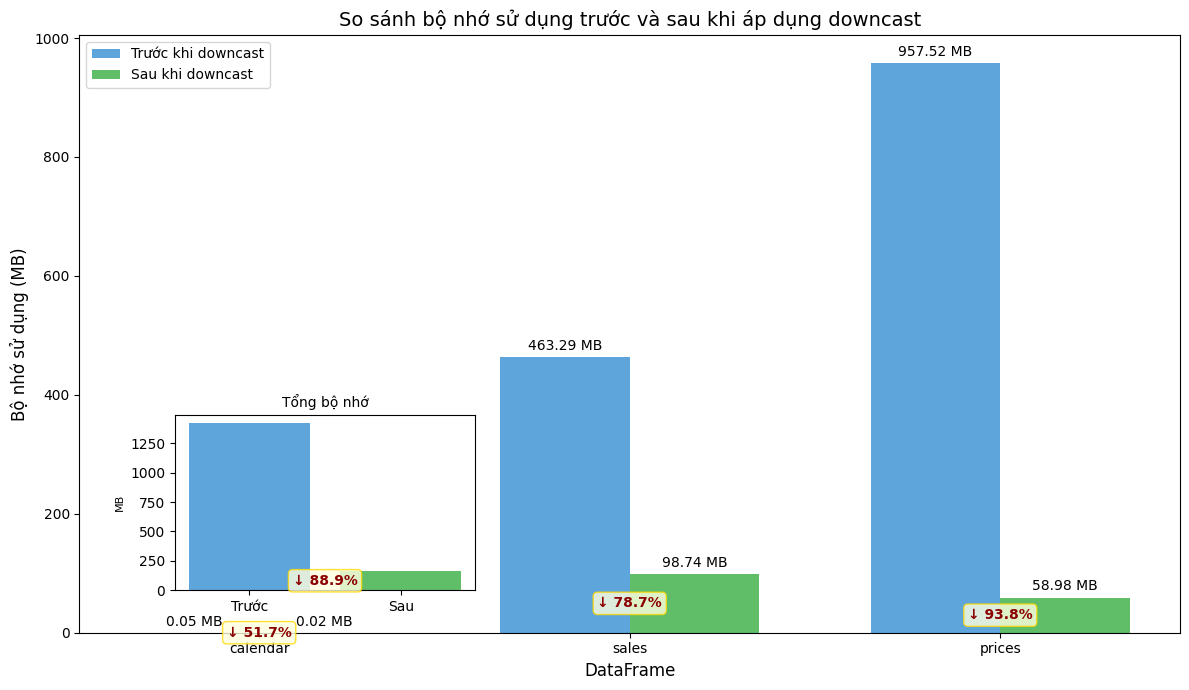

### 💾 Vì sao nên lưu file dưới dạng `.parquet` thay vì `.csv`?

- **Dung lượng nhỏ hơn** nhờ hỗ trợ nén và lưu trữ theo cột.
- **Tốc độ đọc/ghi nhanh hơn** nhiều so với `.csv`.
- **Giữ nguyên kiểu dữ liệu** (dtype), không cần xử lý lại sau khi load.
- **Linh hoạt khi xử lý**, chỉ cần đọc các cột cần thiết.


In [ ]:
calendar.to_parquet('done_cal.parquet')
sales.to_parquet('done_sales.parquet')
prices.to_parquet('done_prices.parquet')

import gc
del calendar, prices, sales
gc.collect()

## Xử lí dữ liệu disasater để thêm một cột dữ liệu cho df gốc.

Quy tắc là thêm một cột disaster_severity_flag nhằm biểu thị mức độ nghiệm trọng của thiên tai ảnh hưởng tới doanh thu của hàng hóa, nếu doanh thu ít mà trong ngày đó xảy ra thiên tai thì chứng tỏ thiên tai có ảnh hưởng nghiêm trọng tới doanh thu, doanh thu càng thấp thì flag có giá trị càng cao và ngược lại, ở đây nhóm em đề xuất sử dụng thang đo là 15( có thể thử nghiệm thêm nhiều thang đo tùy thôi, test nhiều thang để biết thang nào có hiệu suất cao nhất)

In [ ]:
disater = pd.read_csv('../data/us_disasters_m5.csv')

def prep_disater(disater):
    done_dis = disater[['state', 'incident_type', 'incident_begin_date', 'incident_end_date']].copy()
    
    # Chuyển đổi kiểu datetime
    done_dis['incident_begin_date'] = pd.to_datetime(done_dis['incident_begin_date'], errors='coerce')
    done_dis['incident_end_date'] = pd.to_datetime(done_dis['incident_end_date'], errors='coerce')
    
    # Thay thế giá trị thiếu trong incident_end_date
    done_dis['incident_end_date'] = done_dis['incident_end_date'].fillna(
        done_dis['incident_begin_date'] + pd.Timedelta(days=1)
    )
    
    done_dis['incident_begin_date'] = done_dis['incident_begin_date'].dt.tz_localize(None)
    done_dis['incident_end_date'] = done_dis['incident_end_date'].dt.tz_localize(None)
    
    return done_dis

done_dis = prep_disater(disater)

print(done_dis['incident_type'].unique())
print(done_dis['state'].unique())

from sklearn.preprocessing import LabelEncoder

# B1: Gắn tên bang từ state_id để khớp done_dis
label_encoder = LabelEncoder()
done_dis['state'] = label_encoder.fit_transform(done_dis['state'])+1

done_dis.to_parquet('../data/done_dis.parquet')

import gc
del done_dis, disater
gc.collect()

In [ ]:
calendar = pd.read_parquet('done_cal.parquet')

prices = pd.read_parquet('done_prices.parquet')

sales = pd.read_parquet('done_sales.parquet')

done_dis = pd.read_parquet('../data/done_dis.parquet')

# Merge data giữa sales, calendar và prices


1. **Hàm `demand_features(df)`:**
   - Tạo các features dựa trên lịch sử nhu cầu
   - Tính toán giá trị lag (trễ) cho mỗi sản phẩm
   - Tính trung bình động (rolling mean) cho các giá trị lag

2. **Hàm `prep_data(df, drop_d=1000)`:**
   - Loại bỏ dữ liệu cũ trước ngày `drop_d`
   - Chuyển dữ liệu từ dạng rộng (wide) sang dạng dài (long)
   - Tạo features từ dữ liệu nhu cầu (demand)
   - Kết hợp với dữ liệu lịch (calendar) và giá (prices)
   - Mã hóa các biến phân loại (categorical) thành dạng số

In [ ]:
from sklearn.model_selection import train_test_split

LAGS = [7, 28]
WINDOWS = [7, 28]
FIRST = 1942 # first to predict
LENGTH = 28

def demand_features(df):
    """ Derive features from sales data and remove rows with missing values """
    
    for lag in LAGS:
        df[f'lag_t{lag}'] = df.groupby('id')['demand'].transform(lambda x: x.shift(lag)).astype("float32")
        for w in WINDOWS:
            df[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id')[f'lag_t{lag}'].transform(lambda x: x.rolling(w).mean()).astype("float32")
        
    return df

def prep_data(df, drop_d=1000):
    """ Prepare model data sets """
    
    # Kick out old dates
    df = df.drop(["d_" + str(i+1) for i in range(drop_d)], axis=1)

    # Reshape to long
    df = df.assign(id=df.id.str.replace("_evaluation", ""))
    df = df.reindex(columns=df.columns.tolist() + ["d_" + str(FIRST + i) for i in range(LENGTH)])
    df = df.melt(id_vars=["id", "item_id", "store_id", "state_id", "dept_id", "cat_id"], var_name='d', value_name='demand')
    df = df.assign(d=df.d.str[2:].astype("int64"),
                   demand=df.demand.astype("float32"))
    
    # Add demand features
    df = demand_features(df)
    
    # Remove rows with NAs
    df = df[df.d > (drop_d + max(LAGS) + max(WINDOWS))]
 
    # Join calendar & prices
    df = df.merge(calendar, how="left", on="d")
    df = df.merge(prices, how="left", on=["store_id", "item_id", "wm_yr_wk"])
    df = df.drop(["wm_yr_wk"], axis=1)
    
    # Ordinal encoding of remaining categorical fields
    for v in ["item_id", "store_id", "state_id", "dept_id", "cat_id"]:
        df[v] = OrdinalEncoder(dtype="int").fit_transform(df[[v]]).astype("int16") + 1
    
    return df

df = prep_data(sales, 1000 - 28)
print(f'{round(df.memory_usage(deep=True).sum()/1024**2,2)} MB')

In [ ]:
# B3: Khởi tạo cột disaster_type (ban đầu là None)
df['disaster_type'] = None

# B4: Gắn loại thảm họa cho các ngày bị ảnh hưởng
for _, row in done_dis.iterrows():
    mask = (
        (df['state_id'] == row['state']) &
        (df['date'] >= row['incident_begin_date']) &
        (df['date'] <= row['incident_end_date'])
    )
    df.loc[mask, 'disaster_type'] = row['incident_type']

# B5: Tính tổng doanh thu theo loại thảm họa
revenue_by_disaster = df[df['disaster_type'].notna()].groupby('disaster_type')['demand'].sum()

# B6: Chuẩn hóa giá trị doanh thu để gán severity flag
# doanh thu càng thấp => mức độ ảnh hưởng càng nặng
rank = revenue_by_disaster.rank(ascending=True, method='min')  # nhỏ nhất = 1
max_rank = rank.max()
severity_map = (rank / max_rank * 15).astype(int)  # chia thành 1–15

# B7: Gán cột flag theo loại thảm họa
df['disaster_severity_flag'] = df['disaster_type'].map(severity_map)
df['disaster_severity_flag'] = df['disaster_severity_flag'].fillna(0).astype(int)  # nếu không bị thiên tai thì là 0


In [ ]:
import gc
del calendar, prices, sales # sau khi dùng xong và không cần dùng lại thì xóa đi cho đỡ chiếm bộ nhớnhớ
gc.collect()
df['state_id'].unique()
done_dis['state'].unique()

## **Xử lý outlier:** 
* Xác định danh sách ID duy nhất trong dữ liệu
* Duyệt qua từng ID:
  * In tiến độ sau mỗi 1000 ID
  * Lọc dữ liệu theo ID
  * Tạo dataframe chuỗi thời gian với date và demand
  * Tính Exponential Moving Average (EMA)
  * Phát hiện outlier bằng một trong hai cách:
     * Nếu đủ dữ liệu (≥ 2*period): Dùng STL để phân tách xu hướng và mùa vụ, sau đó tìm outlier trong phần dư
     * Nếu không đủ dữ liệu: Áp dụng z-score trực tiếp lên giá trị demand
  * Thay thế các giá trị outlier bằng giá trị EMA tương ứng

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
from statsmodels.tsa.seasonal import STL
from scipy import stats
import matplotlib.dates as mdates

# Đọc dữ liệu
grid_df = pd.read_parquet('../data/train_val.parquet')
grid_df = grid_df.drop(['date'], axis=1)
grid_df = grid_df.dropna(subset=['demand'])
print(grid_df.columns)
duplicate_id_list = grid_df[grid_df.duplicated('id', keep=False)]['id'].unique()
duplicate_id_list = duplicate_id_list[1700:1705]
print(duplicate_id_list)

cal = pd.read_parquet('done_cal.parquet')
# print(cal)

# Để lưu dữ liệu gốc cho việc so sánh sau này
original_grid_df = grid_df.copy()

# Tạo figure cho biểu đồ tổng hợp
plt.figure(figsize=(15, 10))
plt.suptitle('So sánh dữ liệu trước và sau khi xử lý outlier', fontsize=16)

# Số lượng instance được xử lý
processed_instances = 0
# Số lượng outlier được phát hiện
total_outliers = 0

cnt = 0
for instance in duplicate_id_list:
  cnt += 1
  if cnt % 100 == 0:
    break
  filtered_df = grid_df[grid_df.id == instance]

  sales_ts = pd.DataFrame({
     'timestamps': filtered_df['d'].values,
     'demand': filtered_df['demand'].values
  })
  sales_ts['d'] = sales_ts['timestamps'] # keep sales_ts['d'] as integer

  # Merge với calendar_df theo cột 'd'
  sales_ts = sales_ts.merge(cal[['d', 'date']], on='d', how='left')

  sales_ts['timestamps'] = sales_ts['date']
  sales_ts = sales_ts.drop(columns=['date'])

  sales_ts['EMA'] = sales_ts['demand'].ewm(span=2, adjust=False).mean()
  sales_ts['EMA'] = sales_ts['EMA'].apply(math.ceil)

  from statsmodels.tsa.seasonal import STL
  from scipy import stats
  import numpy as np

  # Phân tích chuỗi theo mùa vụ
  stl = STL(sales_ts['demand'], period=30)  # nếu data theo ngày, 7 là 1 tuần
  res = stl.fit()

  residual = res.resid

  # Áp dụng z-score để tìm outlier trong residual
  z = np.abs(stats.zscore(residual))
  threshold = 2.8  # ngưỡng z-score
  outliers = sales_ts[z > threshold]
  print(outliers.head())
  
  # Cập nhật số lượng outliers
  total_outliers += len(outliers)
  
  # Nếu có outlier, vẽ biểu đồ so sánh
  if len(outliers) > 0:
    processed_instances += 1
    
    # Tạo một bản sao của sales_ts để lưu giá trị EMA
    processed_sales_ts = sales_ts.copy()
    for idx, row in outliers.iterrows():
      processed_sales_ts.loc[idx, 'demand'] = row['EMA']

    # Chỉ vẽ biểu đồ cho 4 instance đầu tiên có outlier
    if processed_instances <= 4:
      plt.subplot(2, 2, processed_instances)
      
      # Vẽ dữ liệu gốc
      plt.plot(sales_ts['timestamps'], sales_ts['demand'], 'b-', label='Dữ liệu gốc', alpha=0.7)
      
      # Vẽ dữ liệu đã xử lý
      plt.plot(processed_sales_ts['timestamps'], processed_sales_ts['demand'], 'g-', label='Dữ liệu đã xử lý', alpha=0.7)
      
      # Đánh dấu outliers
      plt.scatter(outliers['timestamps'], outliers['demand'], color='red', s=50, label='Outlier')
      plt.scatter(outliers['timestamps'], outliers['EMA'], color='orange', s=50, marker='x', label='Giá trị thay thế')
      
      # Kết nối outlier trước và sau khi xử lý
      for idx, row in outliers.iterrows():
        plt.plot([row['timestamps'], row['timestamps']], [row['demand'], row['EMA']], 'k--', alpha=0.5)
      
      plt.title(f'ID: {instance} - {len(outliers)} outliers')
      plt.xlabel('Thời gian')
      plt.ylabel('Demand')
      plt.grid(True, alpha=0.3)
      
      # Nếu đây là biểu đồ đầu tiên, hiển thị legend
      if processed_instances == 1:
        plt.legend(loc='upper right')

  # Cập nhật dữ liệu grid_df
  for idx, row in outliers.iterrows():
    grid_df.loc[(grid_df.id == instance) & (grid_df['d'] == row['d']), 'demand'] = row['EMA']

# Điều chỉnh layout
plt.tight_layout(rect=[0, 0, 1, 0.95])  # Điều chỉnh khoảng cách để có chỗ cho tiêu đề lớn
plt.savefig('outlier_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# Tạo biểu đồ thống kê về outliers
plt.figure(figsize=(14, 8))

# Vẽ biểu đồ số lượng outlier theo instance
if processed_instances > 0:
  # Tính toán phân phối lượng outlier trước và sau khi xử lý
  all_ids = []
  original_values = []
  processed_values = []
  
  for instance in duplicate_id_list[:min(cnt, len(duplicate_id_list))]:
    # Lấy dữ liệu gốc và đã xử lý
    orig_df = original_grid_df[original_grid_df.id == instance]
    proc_df = grid_df[grid_df.id == instance]
    
    # Tính tổng demand
    orig_sum = orig_df['demand'].sum()
    proc_sum = proc_df['demand'].sum()
    
    if orig_sum != proc_sum:  # Chỉ xem xét các instance đã thay đổi
      all_ids.append(instance)
      original_values.append(orig_sum)
      processed_values.append(proc_sum)
  
  # Tạo biểu đồ so sánh tổng demand
  plt.subplot(1, 2, 1)
  if len(all_ids) > 0:
    plt.bar(range(len(all_ids)), original_values, alpha=0.6, color='blue', label='Trước khi xử lý')
    plt.bar(range(len(all_ids)), processed_values, alpha=0.6, color='green', label='Sau khi xử lý')
    plt.xticks(range(len(all_ids)), all_ids, rotation=90)
    plt.xlabel('ID')
    plt.ylabel('Tổng Demand')
    plt.title('So sánh tổng demand trước và sau khi xử lý')
    plt.legend()
    plt.grid(True, alpha=0.3)
  
  # Tạo biểu đồ thống kê chung
  plt.subplot(1, 2, 2)
  
  # Tính toán tổng sự khác biệt
  total_diff = sum(abs(np.array(original_values) - np.array(processed_values))) if len(original_values) > 0 else 0
  
  stats_data = [
    processed_instances,  # Số instance có outlier
    total_outliers,       # Tổng số outlier
    total_diff            # Tổng sự khác biệt về demand
  ]
  
  plt.bar(['Instances có outlier', 'Tổng outlier', 'Tổng chênh lệch demand'], stats_data, color=['blue', 'red', 'green'])
  plt.ylabel('Số lượng')
  plt.title('Thống kê về outlier và tác động')
  plt.grid(True, alpha=0.3)
  
  plt.tight_layout()
  plt.savefig('outlier_statistics.png', dpi=300, bbox_inches='tight')
  plt.show()
  
  # In thông tin tổng hợp
  print(f"\nTổng kết:")
  print(f"Đã xử lý {cnt} instance")
  print(f"Có {processed_instances} instance chứa outlier")
  print(f"Tổng số outlier phát hiện được: {total_outliers}")
  print(f"Tổng mức chênh lệch demand: {total_diff}")
  
  # Tạo một bảng so sánh chi tiết
  if len(all_ids) > 0:
    comparison_df = pd.DataFrame({
      'ID': all_ids,
      'Demand gốc': original_values,
      'Demand xử lý': processed_values,
      'Chênh lệch': np.array(processed_values) - np.array(original_values),
      'Phần trăm thay đổi': ((np.array(processed_values) - np.array(original_values)) / np.array(original_values) * 100).round(2)
    })
    print("\nBảng so sánh chi tiết:")
    print(comparison_df)
else:
  plt.text(0.5, 0.5, 'Không tìm thấy outlier nào!', 
         horizontalalignment='center', verticalalignment='center', fontsize=20)
  plt.axis('off')
  plt.tight_layout()
  plt.savefig('outlier_statistics.png', dpi=300, bbox_inches='tight')
  plt.show()

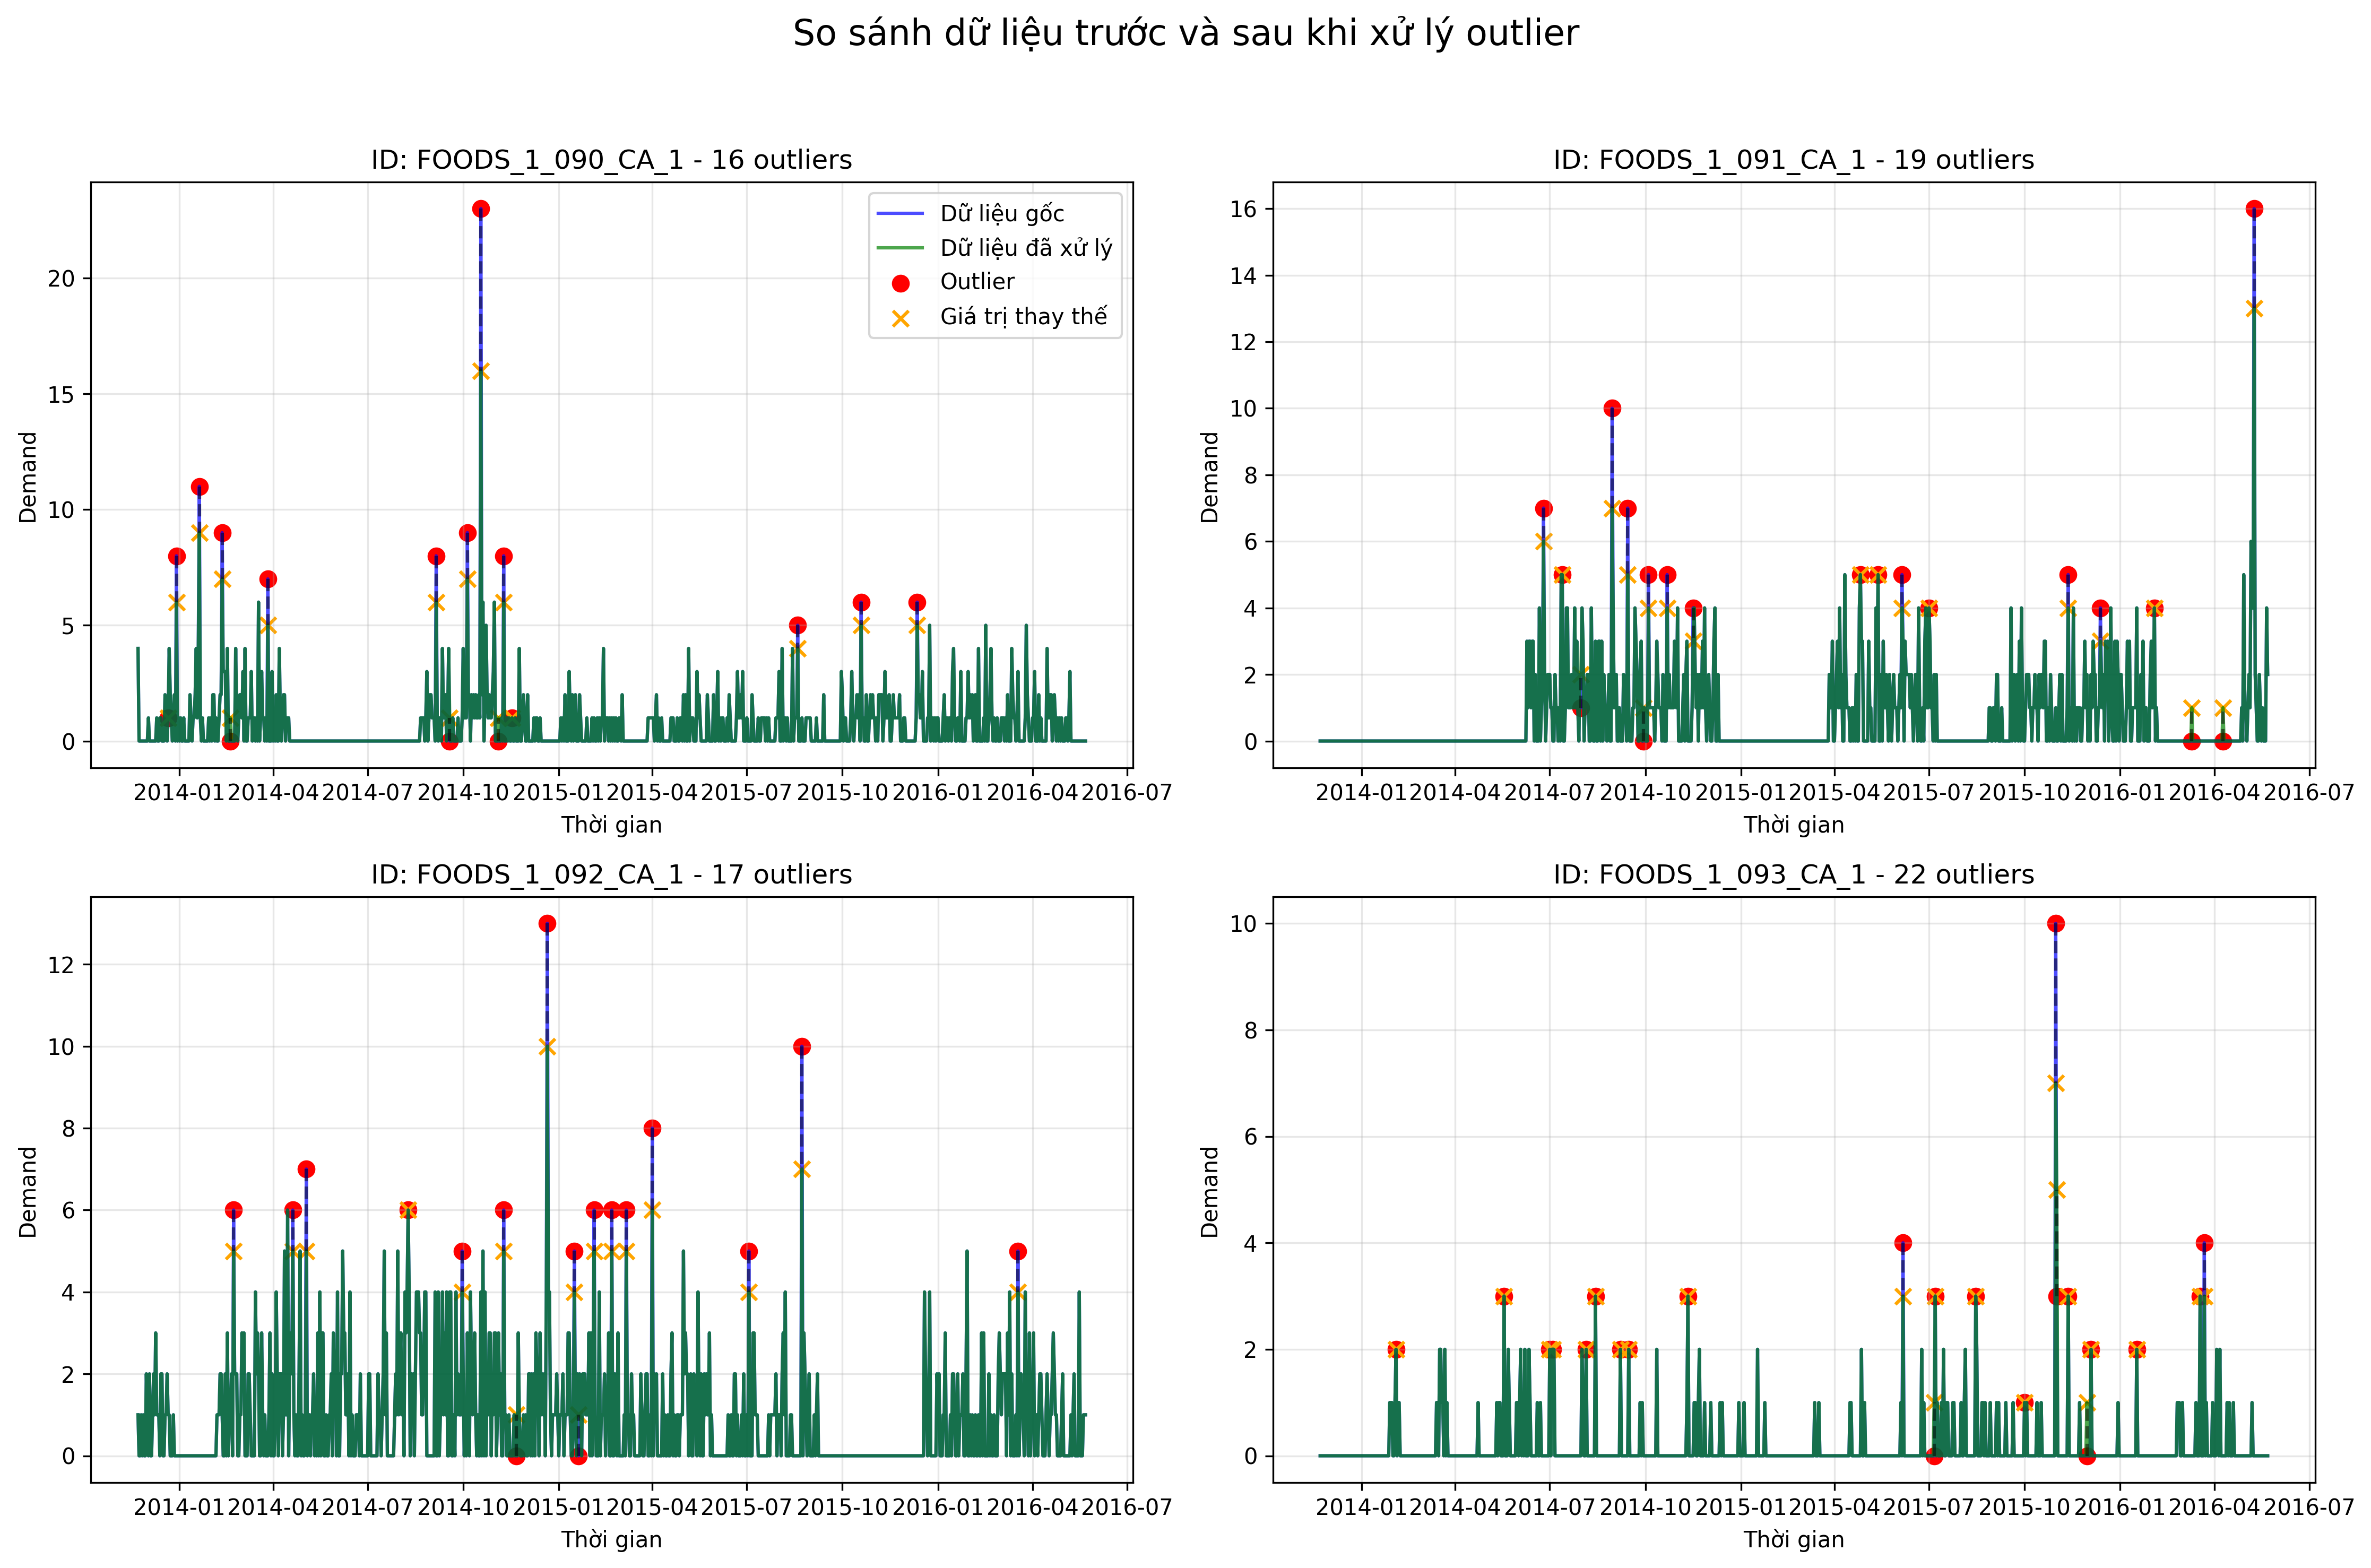

## Xử lý null values

In [ ]:
# Đọc dữ liệu từ file Parquet
grid_df = pd.read_parquet('../data/train_val.parquet')

# Loại bỏ các dòng có giá trị 'demand' bị thiếu
grid_df = grid_df.dropna(subset=['demand'])

# Tạo điều kiện lọc cho sản phẩm cụ thể
m = grid_df.id=='HOBBIES_1_288_CA_1'

# Trích xuất chuỗi thời gian của lượng bán ra ('demand') cho sản phẩm đó
sales_ts = grid_df.loc[m,'demand'].values

# Hàm tìm khoảng thời gian không bán được hàng (gaps)
def gap_finder(ts):
    # Đánh dấu các ngày không có doanh số (demand == 0) là 1, còn lại là 0
    ts = (~(ts > 0)).astype(int)

    # Lặp qua từng ngày để xác định độ dài của mỗi khoảng trống
    for i, val in enumerate(ts):
        if val == 0: 
            continue  # nếu ngày có doanh số, bỏ qua
        else: 
            ts[i] += ts[i-1]  # cộng dồn số ngày liên tiếp không bán được hàng
            ts[i-1] = -1       # đánh dấu ngày trước là đã xử lý
    return ts  # Trả về mảng với các độ dài khoảng trống

# Hàm đếm số lần xuất hiện của mỗi độ dài khoảng trống
def gap_counter(ts):
    # Trả về dictionary: độ dài gap -> số lần xuất hiện
    counts = np.unique(ts, return_counts=True)
    return dict(zip(counts[0], counts[1]))

# Áp dụng hai hàm trên cho sản phẩm cụ thể để lấy thông tin khoảng trống
m = grid_df.id=='HOBBIES_1_288_CA_1'
sales_gaps = gap_counter(gap_finder(grid_df.loc[m,'demand'].values))

# Giả lập một chuỗi thời gian tổng hợp dựa trên khoảng trống có thật
# Giả định xác suất bán được hàng mỗi ngày là như nhau
# Hàm này sẽ tạo chuỗi nhị phân: 1 nếu bán được, 0 nếu không

def synth_sales(gaps_dict, min_gap=1000):
    # Lấy số ngày bán được hàng (tức là các gap có độ dài = 0)
    sum_sale_days = gaps_dict.get(0, 0)  # nếu không có key 0 thì trả về 0
    
    # Tổng số ngày trong chuỗi dữ liệu (bao gồm cả ngày bán và không bán)
    sum_days = sum(gaps_dict.values())
    
    # Tổng số ngày trong các khoảng trống dài hơn `min_gap`
    sum_gap_length = sum([k for k in [*sales_gaps.keys()] if k > min_gap])
    
    # Tính xác suất bán hàng: loại bỏ những gap quá dài khỏi mẫu tính
    p = sum_sale_days / (sum_days - sum_gap_length)
    
    # Tạo chuỗi nhị phân với xác suất p, độ dài = tổng số ngày
    return np.random.binomial(1, p, sum(gaps_dict.values()))

# Áp dụng các hàm để đếm khoảng trống trong chuỗi dữ liệu tổng hợp
synth_sales_gaps = gap_counter(gap_finder(synth_sales(sales_gaps)))

# In ra thống kê khoảng trống trong dữ liệu tổng hợp
synth_sales_gaps

### Phát hiện Hết Hàng Dựa trên Dữ liệu Bán Hàng

---

Đoạn code này thực hiện việc phát hiện các ngày **hết hàng tiềm năng** (out-of-stock) cho một sản phẩm bằng cách mô phỏng và so sánh với dữ liệu thực tế. Toàn bộ quy trình gồm 4 bước chính:

---

### 📌 1. Mô phỏng chuỗi bán hàng (Simulation)
- Giả lập chuỗi bán hàng nhị phân (1: bán được, 0: không bán) dựa trên xác suất thực tế.
- Chạy mô phỏng 1,000 lần để thu thập thống kê về **độ dài các khoảng trống không bán được hàng (gaps)**.
- Tính tần suất xuất hiện của từng độ dài gap qua `gap_length_prob`.

---

### 📌 2. Xác định ngưỡng gap bất thường (`min_gap_length`)
- Những gap hiếm xuất hiện (dưới 5% trong mô phỏng) được coi là bất thường.
- Tìm **độ dài nhỏ nhất** trong số các gap bất thường và gán cho `min_gap_length`.
- Giả định: các gap dài bất thường có thể do sản phẩm thật sự hết hàng, không phải ngẫu nhiên.

---

### 📌 3. Tái mô phỏng để hiệu chỉnh ngưỡng
- Các gap dài bất thường được loại bỏ khỏi việc tính xác suất bán hàng trong mô phỏng tiếp theo.
- Lặp lại mô phỏng cho đến khi `min_gap_length` ổn định (không thay đổi giữa các vòng lặp).

---

### 📌 4. Tạo feature `out_of_stock`
- Áp dụng hàm phát hiện gap cho dữ liệu thực tế.
- Nếu một gap dài hơn `min_gap_length` → đánh dấu là `True` (tức sản phẩm bị hết hàng).
- Trả về chuỗi boolean `gf`, biểu thị các ngày sản phẩm có thể đã hết hàng.

---

🔍 **Ý nghĩa ứng dụng:** Giúp tách biệt các khoảng trống do yếu tố thị trường (không có nhu cầu) với các khoảng trống do nguyên nhân logistics (hết hàng) – hỗ trợ cho việc phân tích tồn kho, dự báo nhu cầu và tối ưu chuỗi cung ứng.


In [ ]:
# As you can see we dont have results > 20. 
# To make sure this is a consistent result lets run simulation 1,000 times:
# >>>> n equal 1,000 might be an overshot for some ids.

n=1000

sym_df = pd.DataFrame([gap_counter(gap_finder(synth_sales(sales_gaps))) for i in range(n)])
gap_length_prob = (sym_df.sum(axis=0)/n).sort_index()
gap_length_prob

# The shortest gap that has been seen in less than 5% of simulated series:
min_gap_length = min(gap_length_prob[gap_length_prob<0.05].index)
min_gap_length

# Now we exclude the gaps longer than min_gap_length from 'probability of sale' calculation, 
# because we assume them to be non-random.
# Run the simulation recursively until the min_gap_length does not decrease:

n=1000
new_min_gap_length = 0

while new_min_gap_length != min_gap_length:
    
    if new_min_gap_length!=0: min_gap_length=new_min_gap_length

    sym_df = pd.DataFrame([gap_counter(gap_finder(synth_sales(sales_gaps, min_gap_length))) for i in range(n)])
    gap_length_prob = (sym_df.sum(axis=0)/n).sort_index()

    # Lets find the shortes gap that has been seen in les than 5% of simulated series:
    new_min_gap_length = min(gap_length_prob[gap_length_prob<0.05].index)

min_gap_length

# Finally we need to make a feature 'out_of_stock' for the product:
m = grid_df.id=='HOBBIES_1_288_CA_1'
idx = grid_df.loc[m,'demand'].index

gf = pd.Series(gap_finder(grid_df.loc[m,'demand'].values), index = idx)
gf = gf.replace(-1,np.nan).fillna(method='backfill') 
gf = gf > min_gap_length
gf

In [ ]:
grid_df['out_of_stock'] = 0
n = 1000
prods = list(grid_df.id.unique())[1700:1705]
gap_length_list = []

for prod_id in tqdm(prods):
    m = grid_df.id == prod_id
    idx = grid_df.loc[m, 'demand'].index

    sales_gaps = gap_counter(gap_finder(grid_df.loc[m, 'demand'].values))
    sym_df = pd.DataFrame([gap_counter(gap_finder(synth_sales(sales_gaps))) for _ in range(n)])
    gap_length_prob = (sym_df.sum(axis=0) / n).sort_index()

    # Nếu không có giá trị nào < 0.05 thì bỏ qua sản phẩm này
    if (gap_length_prob < 0.05).sum() == 0:
        continue

    min_gap_length = min(gap_length_prob[gap_length_prob < 0.05].index)
    new_min_gap_length = 0

    while new_min_gap_length < min_gap_length:
        if new_min_gap_length != 0:
            min_gap_length = new_min_gap_length

        sym_df = pd.DataFrame([gap_counter(gap_finder(synth_sales(sales_gaps, min_gap_length))) for _ in range(n)])
        gap_length_prob = (sym_df.sum(axis=0) / n).sort_index()

        if (gap_length_prob < 0.05).sum() == 0:
            break
        new_min_gap_length = min(gap_length_prob[gap_length_prob < 0.05].index)

    gf = pd.Series(gap_finder(grid_df.loc[m, 'demand'].values), index=idx)
    gf = gf.replace(-1, np.nan).fillna(method='backfill')
    gf = gf > min_gap_length
    grid_df.loc[m, 'out_of_stock'] = gf * 1
    gap_length_list.append(min_gap_length)

In [ ]:
plt.figure(figsize=(15, 25))

for i, prod_id in enumerate(prods):
    plt.subplot(5, 1, i + 1)
    m = grid_df.id == prod_id
    prod_df = grid_df.loc[m]

    plt.plot(prod_df['d'], prod_df['demand'], label='Demand', color='blue')

    out_days = prod_df[prod_df['out_of_stock'] == 1]
    plt.scatter(out_days['d'], out_days['demand'], color='red', label='Out of Stock', zorder=5)

    plt.title(f'{prod_id}')
    plt.xlabel('Date')
    plt.ylabel('Demand')
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

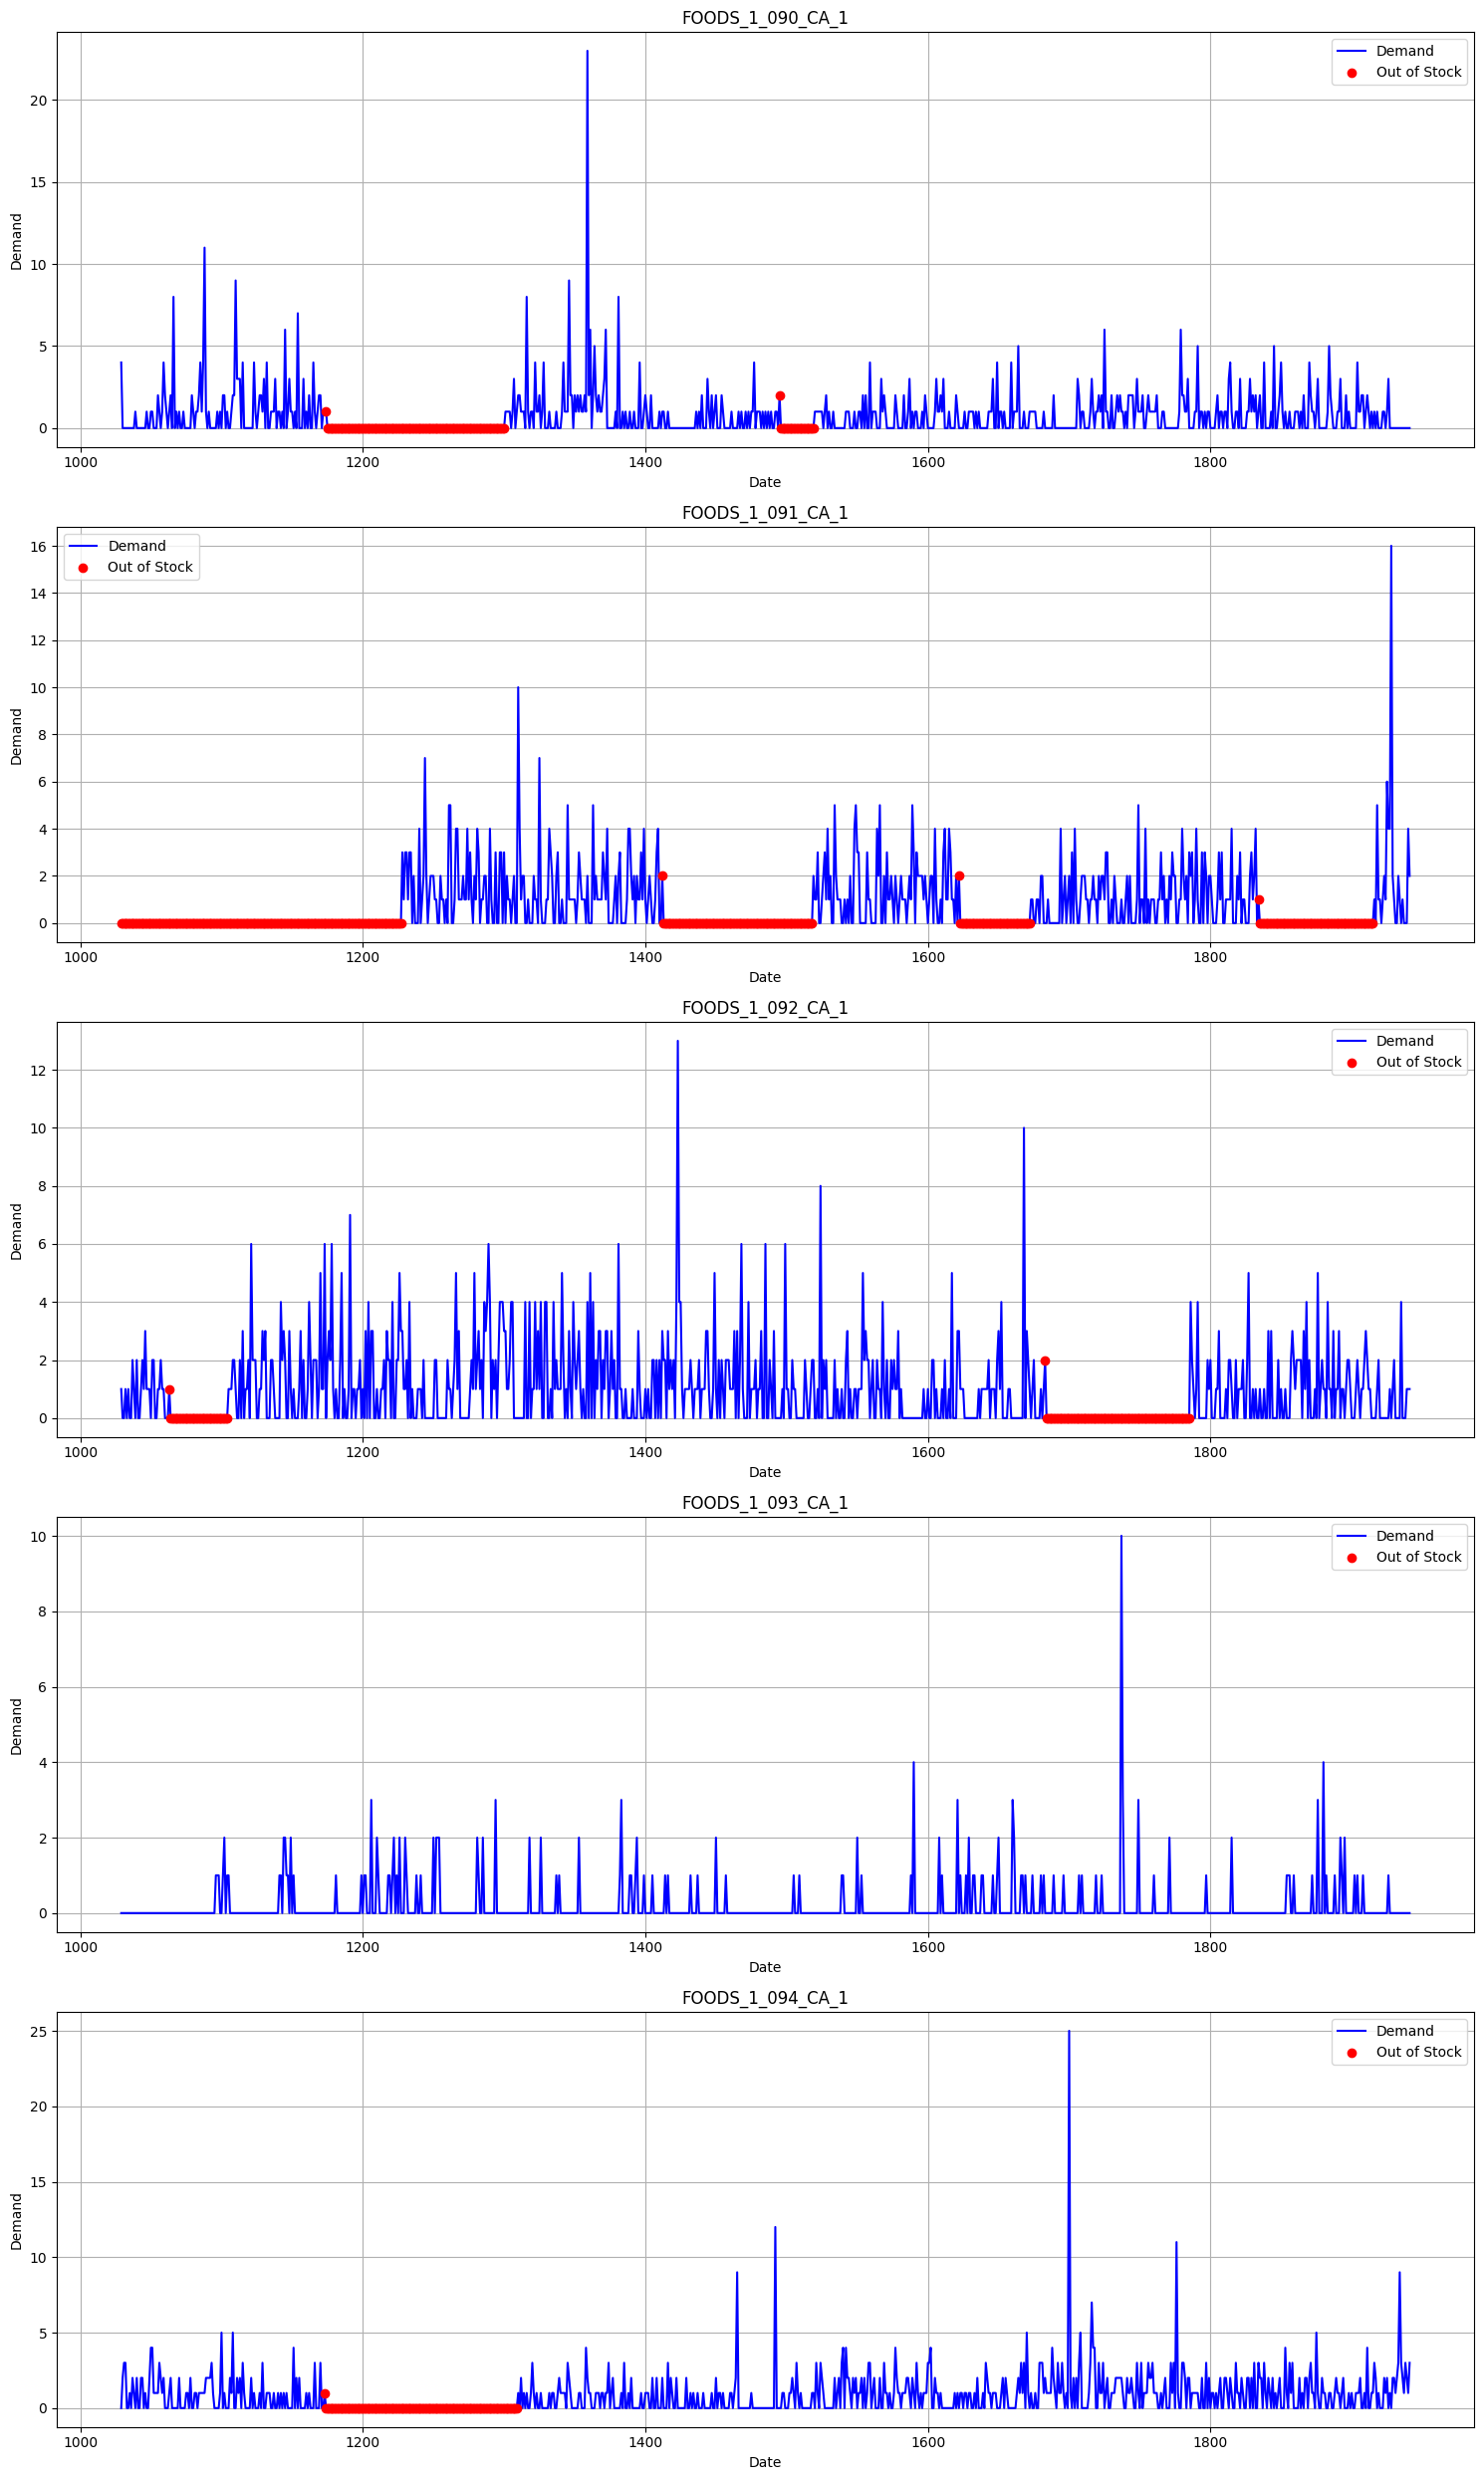

# Features Engineering
Phần này sẽ giải quyết việc chọn các feature như thế nào cho phù hợp và tối ưu để huấn luyện model.

Các chiến thuật Tạo mới đặc trưng mới, biến đổi đặc trưng

Chọn lựa đặc trưng: 

   - Dùng các mô hình máy học LASSO, Ridge, ElasticNet, Decision Tree, Random Forest để tìm các đặc trưng quan trọng

   - Dựa trên phân tích thống kê ở bước EDA

   - Chiến thuật để bỏ đặc trưng

## 🔍 Tạo đặc trưng thời gian từ dữ liệu demand

Để mô hình dự đoán chính xác hơn, ta tạo ra các đặc trưng từ dữ liệu quá khứ, đồng thời mong muốn học được món hàng đang được dự đoán có đang nằm gần hoặc trong xu hướng hay không:

- **Lag features**: Doanh thu tại các mốc thời gian lùi lại, ví dụ 7 hoặc 28 ngày trước. Điều này giúp mô hình nhận biết chu kỳ tuần / tháng.
- **Rolling mean features**: Trung bình động trong 7 hoặc 28 ngày gần mốc lag, giúp mô hình hiểu xu hướng tăng giảm của nhu cầu.
- Tất cả đặc trưng đều được tính theo từng `id` (mỗi sản phẩm tại từng cửa hàng cụ thể).

Hàm `demand_features(df)` sẽ tự động tạo ra các cột này để sử dụng trong huấn luyện mô hình.

Để hiểu rõ hơn ví dụ nếu như là lag_t7 cho ngày thứ 100 của món hàng A sẽ là doanh thu của ngày thứ 93. còn, rolling_mean_lag7_w28 của ngày thứ 100 của món hàng A sẽ là doanh thu trung bình từ ngày 72 (=100 - 28) tới ngày 78 (7 ngày).


In [ ]:
calendar = pd.read_parquet('done_cal.parquet')
sales = pd.read_parquet('done_sales.parquet')
prices = pd.read_parquet('done_prices.parquet')

In [ ]:
LAGS = [7, 28]
WINDOWS = [7, 28]
FIRST = 1942 # first to predict
LENGTH = 28

def demand_features(df):
    """ Derive features from sales data and remove rows with missing values """

    for lag in LAGS:
        df[f'lag_t{lag}'] = df.groupby('id')['demand'].transform(lambda x: x.shift(lag)).astype("float32")
        for w in WINDOWS:
            df[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id')[f'lag_t{lag}'].transform(lambda x: x.rolling(w).mean()).astype("float32")

    return df

def demand_features_eval(df):
    """ Same as demand_features but for the step-by-step evaluation """
    out = df.groupby('id', sort=False).last()
    for lag in LAGS:
        out[f'lag_t{lag}'] = df.groupby('id', sort=False)['demand'].nth(-lag-1).astype("float32")
        for w in WINDOWS:
            out[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id', sort=False)['demand'].nth(list(range(-lag-w, -lag))).groupby('id', sort=False).mean().astype("float32")

    return out.reset_index()

def prep_data(df, drop_d=1000):
    """ Prepare model data sets """

    # Kick out old dates
    df = df.drop(["d_" + str(i+1) for i in range(drop_d)], axis=1)

    # Reshape to long
    df = df.assign(id=df.id.str.replace("_evaluation", ""))
    df = df.reindex(columns=df.columns.tolist() + ["d_" + str(FIRST + i) for i in range(LENGTH)])
    df = df.melt(id_vars=["id", "item_id", "store_id", "state_id", "dept_id", "cat_id"], var_name='d', value_name='demand')
    df = df.assign(d=df.d.str[2:].astype("int64"),
                   demand=df.demand.astype("float32"))

    # Add demand features
    df = demand_features(df)

    # Remove rows with NAs
    df = df[df.d > (drop_d + max(LAGS) + max(WINDOWS))]

    # Join calendar & prices
    df = df.merge(calendar, how="left", on="d")
    df = df.merge(prices, how="left", on=["store_id", "item_id", "wm_yr_wk"])
    df = df.drop(["wm_yr_wk"], axis=1)

    # Ordinal encoding of remaining categorical fields
    for v in ["item_id", "store_id", "state_id", "dept_id", "cat_id"]:
        df[v] = OrdinalEncoder(dtype="int").fit_transform(df[[v]]).astype("int16") + 1

    # Determine list of covariables
    x = list(set(df.columns) - {'id', 'd', 'demand'})

    # Split into test, valid, train
    test = df[df.d >= FIRST - max(LAGS) - max(WINDOWS) - 28]
    df = df[df.d < FIRST]

    return df, test, x

df, test, x = prep_data(sales, 1000 - 28)

del sales, prices, calendar,test
gc.collect()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_demand_feature_correlation(df):
    # Lấy danh sách các cột được tạo bởi demand_features
    demand_cols = [col for col in df.columns if col.startswith("lag_t") or col.startswith("rolling_mean")]

    # Thêm cột demand để so sánh tương quan
    corr_cols = demand_cols + ["demand"]

    # Loại bỏ hàng có NaN (do shift và rolling tạo ra)
    df_corr = df[corr_cols].dropna()

    # Tính ma trận tương quan
    corr = df_corr.corr()

    # Vẽ heatmap
    plt.figure(figsize=(12, 8))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True)
    plt.title("Ma trận tương quan giữa các đặc trưng demand và cột demand")
    plt.show()
plot_demand_feature_correlation(df)

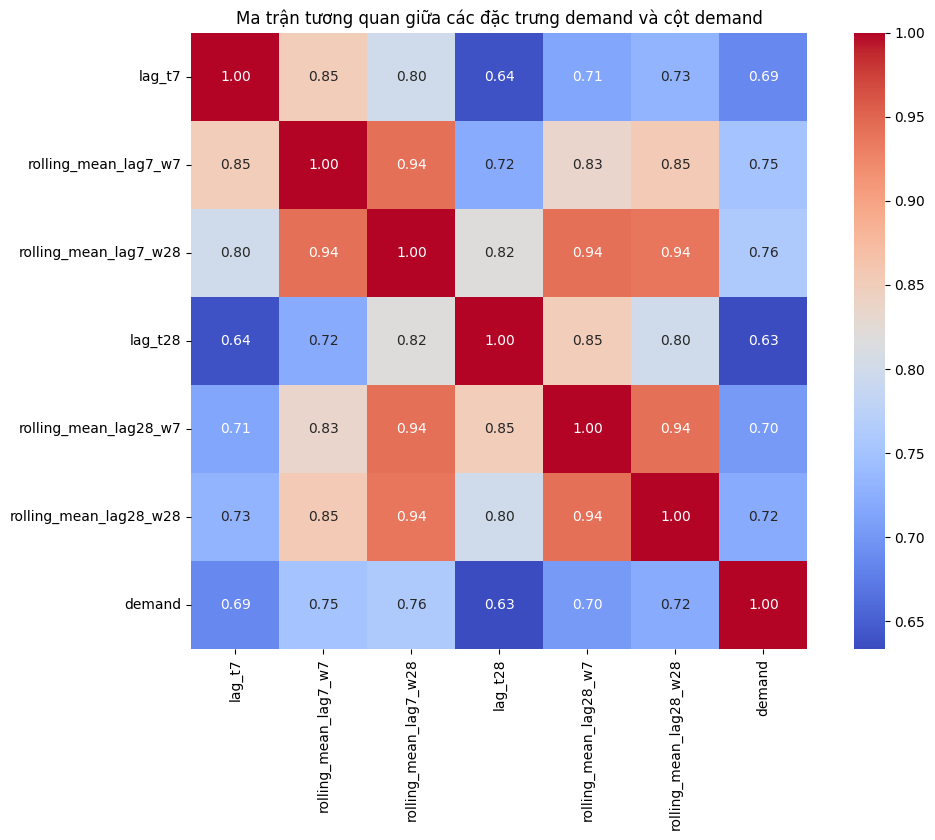

## Nhận xét ma trận tương quan
Thông qua, ma trận dễ dàng thấy demand ảnh hưởng khá nhiều bởi các feature đã được tạo ra. Tuy nhiên, cũng có thể thấy các cột rolling_mean có độ tương quan cao khi bắt cặp với nhau.

Dựa trên, độ tương quan giữa demand và các cột rolling_mean, nhóm quyết định giữ lại rolling_mean_lag7_w7 và rolling_mean_lag7_w28 và xóa đi 2 rolling_mean còn lại vì có độ tương quan cao với 2 rolling_mean_lag7_w7 còn lại

In [ ]:
df.drop(['rolling_mean_lag7_w7', 'rolling_mean_lag7_w28'], axis=1, inplace=True)

def plot_demand_feature_scatter(df, sample_size=1000, use_log=False, clip_outliers=True):
    import seaborn as sns
    import matplotlib.pyplot as plt

    demand_cols = [col for col in df.columns if col.startswith("lag_t") or col.startswith("rolling_mean")]
    df_sample = df[demand_cols + ["demand"]].dropna().sample(n=sample_size, random_state=42)

    for col in demand_cols:
        plt.figure(figsize=(6, 4))
        sns.scatterplot(data=df_sample, x=col, y="demand", alpha=0.5)

        if clip_outliers:
            plt.xlim(df_sample[col].quantile(0.01), df_sample[col].quantile(0.99))
            plt.ylim(df_sample["demand"].quantile(0.01), df_sample["demand"].quantile(0.99))

        if use_log:
            plt.xscale("log")
            plt.yscale("log")

        plt.title(f"{col} vs demand")
        plt.xlabel(col)
        plt.ylabel("demand")
        plt.grid(True)
        plt.tight_layout()
        plt.show()

plot_demand_feature_scatter(df)

del df,x
gc.collect()

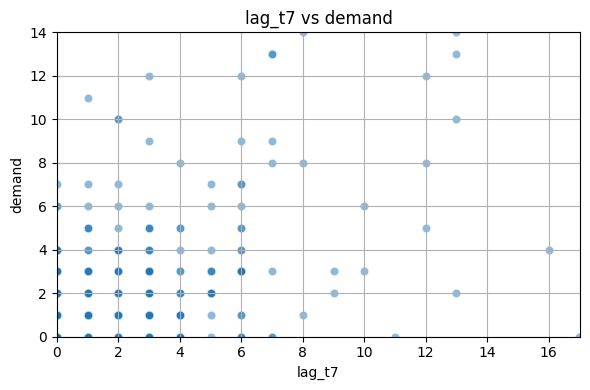

## Tìm kiếm thêm đặc trưng mới
Nhận thấy việc bán lẻ, các cửa hàng sẽ có xu hướng bị ảnh hưởng bởi các đặc trưng như giá vàng, sự kiến MMA, thiên tai

### 🟡 1. Giá vàng
#### Giả định ảnh hưởng:

- Giá vàng thường được xem như một chỉ báo kinh tế. Khi giá vàng tăng mạnh, nó thường phản ánh tâm lý bất ổn kinh tế, khiến người dân tiết kiệm hơn —> giảm chi tiêu ở siêu thị.

- Ngược lại, giá vàng giảm có thể khiến người dân thấy kinh tế ổn định hơn —> tăng chi tiêu.

#### Cách kiểm chứng dữ liệu:

- Lấy dữ liệu giá vàng hàng ngày hoặc hàng tuần.

- Kết hợp với dữ liệu bán hàng theo thời gian.

In [ ]:
df = pd.read_parquet('../../data/train_val.parquet').head(1000000)
print(df.columns)
print(df['state_id'].unique())

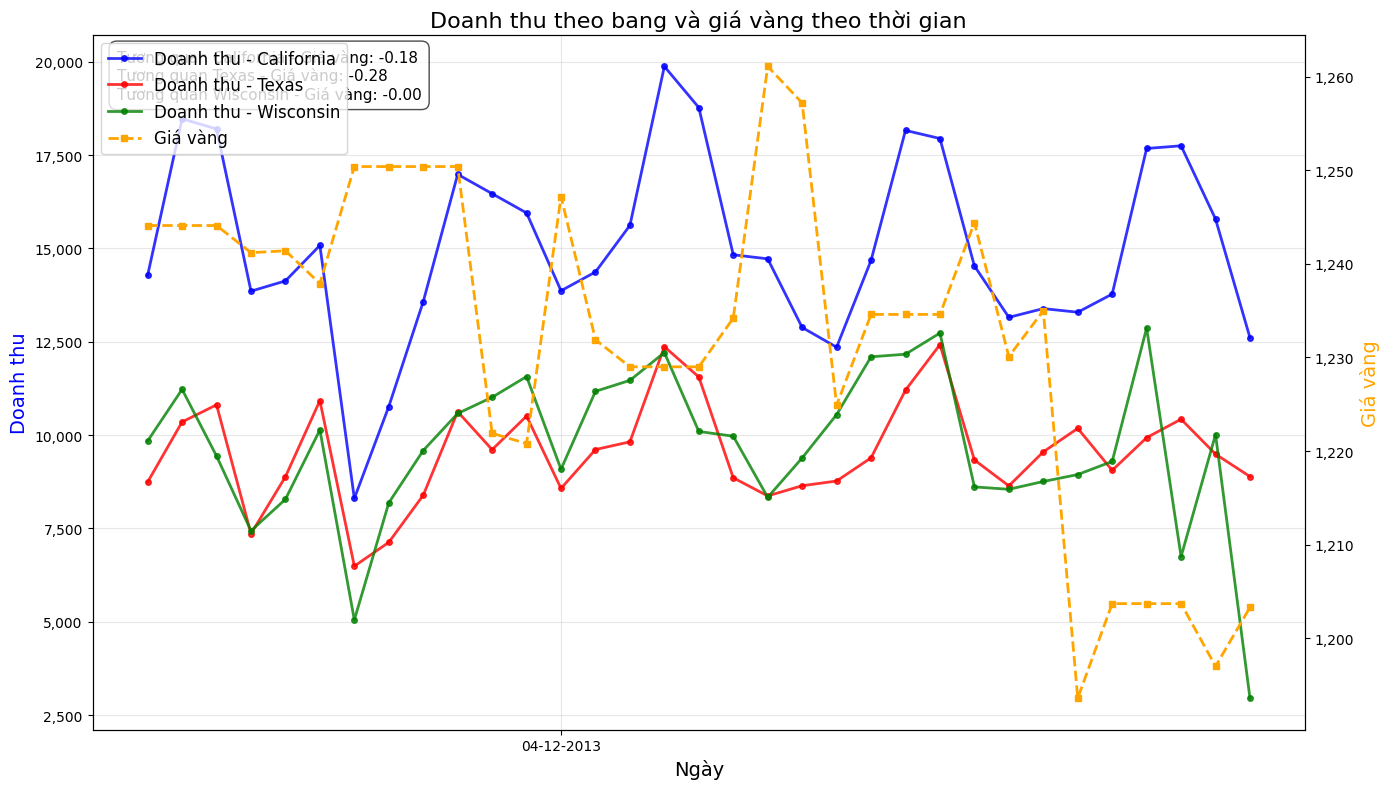

In [ ]:
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# Chuyển đổi state_id sang tên bang
state_mapping = {
    1: 'California',
    2: 'Texas',
    3: 'Wisconsin'
}

# Thêm cột state_name vào DataFrame
df['state_name'] = df['state_id'].map(state_mapping)

# Chuyển đổi cột ngày sang định dạng datetime nếu chưa phải
df['date'] = pd.to_datetime(df['date'])

# Nhóm dữ liệu theo ngày và bang, tính tổng doanh thu cho tất cả sản phẩm
daily_revenue_by_state = df.groupby(['date', 'state_name'])['demand'].sum().unstack()

# Lấy giá vàng cho mỗi ngày (giả sử giá vàng giống nhau trong một ngày)
gold_prices = df.groupby('date')['gold_price'].first()

# Tạo một figure với 2 trục y
fig, ax1 = plt.subplots(figsize=(14, 8))

# Đặt trục y thứ hai cho giá vàng
ax2 = ax1.twinx()

# Màu sắc cho các đường doanh thu của từng bang
colors = ['blue', 'red', 'green']

# Vẽ đường doanh thu cho mỗi bang trên trục y thứ nhất
for i, state in enumerate(daily_revenue_by_state.columns):
    ax1.plot(
        daily_revenue_by_state.index,
        daily_revenue_by_state[state],
        color=colors[i],
        marker='o',
        markersize=4,
        linewidth=2,
        alpha=0.8,
        label=f'Doanh thu - {state}'
    )

# Vẽ đường giá vàng trên trục y thứ hai
ax2.plot(
    gold_prices.index,
    gold_prices.values,
    color='orange',
    marker='s',
    markersize=4,
    linewidth=2,
    linestyle='--',
    label='Giá vàng'
)

# Định dạng trục x để hiển thị label cứ mỗi 50 ngày
# Xác định ngày đầu tiên và cuối cùng trong dữ liệu
first_date = min(daily_revenue_by_state.index.min(), gold_prices.index.min())
last_date = max(daily_revenue_by_state.index.max(), gold_prices.index.max())

# Tạo một mảng các ngày với khoảng cách 50 ngày
date_range = pd.date_range(start=first_date, end=last_date, freq='50D')

# Thiết lập các vị trí và nhãn cho trục x
ax1.xaxis.set_major_locator(mdates.DayLocator(interval=50))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%d-%m-%Y'))

# Đặt tiêu đề và nhãn
ax1.set_title('Doanh thu theo bang và giá vàng theo thời gian', fontsize=16)
ax1.set_xlabel('Ngày', fontsize=14)
ax1.set_ylabel('Doanh thu', fontsize=14, color='blue')
ax2.set_ylabel('Giá vàng', fontsize=14, color='orange')

# Xoay nhãn trục x để dễ đọc
plt.xticks(rotation=45)

# Định dạng số lớn hơn với dấu phẩy ngăn cách hàng nghìn
def thousands_formatter(x, pos):
    return f'{int(x):,}'

ax1.yaxis.set_major_formatter(FuncFormatter(thousands_formatter))
ax2.yaxis.set_major_formatter(FuncFormatter(thousands_formatter))

# Kết hợp legends từ cả hai trục
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', frameon=True, fontsize=12)

# Thêm lưới để dễ đọc
ax1.grid(True, alpha=0.3)

# Tính tương quan giữa giá vàng và doanh thu cho mỗi bang và hiển thị
corr_text = []
for state in daily_revenue_by_state.columns:
    # Kết hợp dữ liệu để tính toán tương quan
    state_data = pd.DataFrame({
        'revenue': daily_revenue_by_state[state],
        'gold_price': gold_prices
    }).dropna()

    corr = state_data['revenue'].corr(state_data['gold_price'])
    corr_text.append(f'Tương quan {state} - Giá vàng: {corr:.2f}')

# Hiển thị thông tin tương quan ở góc trái trên
ax1.annotate(
    '\n'.join(corr_text),
    xy=(0.02, 0.98),
    xycoords='axes fraction',
    va='top',
    ha='left',
    fontsize=11,
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.7)
)

plt.tight_layout()
plt.show()

### 🥋 2. Sự kiện MMA
#### Giả định ảnh hưởng:

- Các sự kiện thể thao lớn (đặc biệt là UFC, WWE...) thường dẫn tới mua sắm trước sự kiện như đồ ăn nhanh, bia, snack, v.v.

- Doanh số ở các siêu thị thường tăng nhẹ vào 1–2 ngày trước và ngày diễn ra sự kiện.

In [ ]:
# Lấy ngày có UFC (flag_ufc = 1)
ufc_days = df.loc[df['flag_ufc'] == 1, 'date'].unique()

# Tạo figure
fig, ax = plt.subplots(figsize=(14, 8))

# Màu sắc cho các đường doanh thu của từng bang
colors = ['blue', 'red', 'green']

# Vẽ đường doanh thu cho mỗi bang
for i, state in enumerate(daily_revenue_by_state.columns):
    ax.plot(
        daily_revenue_by_state.index, 
        daily_revenue_by_state[state],
        color=colors[i],
        marker='o',
        markersize=4,
        linewidth=2,
        alpha=0.8,
        label=f'Doanh thu - {state}'
    )

# Đánh dấu những ngày có UFC
for date in ufc_days:
    # Vẽ một vùng tô màu dọc tại ngày có UFC
    ax.axvline(x=date, color='purple', alpha=0.3, linestyle='--', linewidth=1.5)
    
    # Thêm một điểm nhỏ ở phía trên biểu đồ để đánh dấu ngày có UFC
    ymax = ax.get_ylim()[1]
    ax.plot(date, ymax * 0.95, 'D', color='purple', markersize=8)

# Chú thích riêng cho UFC
from matplotlib.lines import Line2D
ufc_legend = Line2D([0], [0], marker='D', color='w', markerfacecolor='purple', 
                    markersize=8, label='Ngày có UFC')
handles, labels = ax.get_legend_handles_labels()
handles.append(ufc_legend)
ax.legend(handles=handles, loc='upper left', frameon=True, fontsize=12)

# Định dạng trục x để hiển thị label cứ mỗi 50 ngày
ax.xaxis.set_major_locator(mdates.DayLocator(interval=50))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%m-%Y'))
plt.xticks(rotation=45)

# Đặt tiêu đề và nhãn
ax.set_title('Doanh thu theo bang và ngày có UFC', fontsize=16)
ax.set_xlabel('Ngày', fontsize=14)
ax.set_ylabel('Doanh thu', fontsize=14)

# Định dạng số lớn hơn với dấu phẩy ngăn cách hàng nghìn
def thousands_formatter(x, pos):
    return f'{int(x):,}'

ax.yaxis.set_major_formatter(FuncFormatter(thousands_formatter))

# Thêm lưới để dễ đọc
ax.grid(True, alpha=0.3)

# Thêm văn bản chú thích
ax.annotate(
    'Ngày có UFC được đánh dấu bằng đường kẻ dọc và biểu tượng kim cương',
    xy=(0.5, 0.02),
    xycoords='axes fraction',
    ha='center',
    va='bottom',
    fontsize=11,
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.7)
)

plt.tight_layout()
plt.show()

### 🌪 3. Ngày diễn ra thiên tai
#### Giả định ảnh hưởng:

- Trước thiên tai (như bão, lốc xoáy, cháy rừng), người dân thường tăng mua hàng thiết yếu: nước, đồ hộp, nến, pin, thuốc.

- Sau thiên tai, có thể doanh số giảm tạm thời nếu giao thông, điện bị gián đoạn.

### Độ ẩm

In [ ]:
# Chuyển đổi state_id sang tên bang
state_mapping = {
    1: 'California',
    2: 'Texas',
    3: 'Wisconsin'
}

# Thêm cột state_name vào DataFrame
df['state_name'] = df['state_id'].map(state_mapping)

# Chuyển đổi cột ngày sang định dạng datetime nếu chưa phải
df['date'] = pd.to_datetime(df['date'])

# Nhóm dữ liệu theo ngày và bang, tính tổng doanh thu cho tất cả sản phẩm
daily_revenue_by_state = df.groupby(['date', 'state_name'])['demand'].sum().unstack()

# Nhóm dữ liệu theo ngày và bang để lấy độ ẩm riêng cho từng bang
humidity_by_state = df.groupby(['date', 'state_name'])['humidity'].mean().unstack()

# Tạo figure với 3 subplot, mỗi subplot cho một bang
fig, axes = plt.subplots(3, 1, figsize=(14, 18), sharex=True)

# Màu sắc cho các đường
colors_revenue = ['blue', 'red', 'green']
colors_humidity = ['dodgerblue', 'lightcoral', 'lightgreen']

# Xử lý từng bang
for i, state in enumerate(daily_revenue_by_state.columns):
    # Tạo trục y thứ hai cho độ ẩm
    ax1 = axes[i]
    ax2 = ax1.twinx()
    
    # Vẽ đường doanh thu
    ax1.plot(
        daily_revenue_by_state.index, 
        daily_revenue_by_state[state],
        color=colors_revenue[i],
        marker='o',
        markersize=4,
        linewidth=2,
        alpha=0.8,
        label=f'Doanh thu'
    )
    
    # Vẽ đường độ ẩm
    ax2.plot(
        humidity_by_state.index,
        humidity_by_state[state],
        color=colors_humidity[i],
        marker='s',
        markersize=4,
        linewidth=2,
        linestyle='--',
        alpha=0.8,
        label=f'Độ ẩm'
    )
    
    # Đặt tiêu đề và nhãn
    ax1.set_title(f'Doanh thu và độ ẩm theo thời gian cho {state}', fontsize=14)
    ax1.set_ylabel('Doanh thu', fontsize=12, color=colors_revenue[i])
    ax2.set_ylabel('Độ ẩm (%)', fontsize=12, color=colors_humidity[i])
    
    # Tính và hiển thị hệ số tương quan
    state_data = pd.DataFrame({
        'revenue': daily_revenue_by_state[state],
        'humidity': humidity_by_state[state]
    }).dropna()
    
    corr = state_data['revenue'].corr(state_data['humidity'])
    ax1.annotate(
        f'Hệ số tương quan: {corr:.2f}',
        xy=(0.02, 0.95),
        xycoords='axes fraction',
        va='top',
        ha='left',
        fontsize=11,
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.7)
    )
    
    # Định dạng số lớn hơn với dấu phẩy ngăn cách hàng nghìn
    def thousands_formatter(x, pos):
        return f'{int(x):,}'
    
    ax1.yaxis.set_major_formatter(FuncFormatter(thousands_formatter))
    
    # Kết hợp legends từ cả hai trục
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right', frameon=True, fontsize=10)
    
    # Thêm lưới để dễ đọc
    ax1.grid(True, alpha=0.3)

# Định dạng trục x để hiển thị label cứ mỗi 50 ngày
axes[2].xaxis.set_major_locator(mdates.DayLocator(interval=50))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%d-%m-%Y'))
axes[2].set_xlabel('Ngày', fontsize=12)

# Xoay nhãn trục x để dễ đọc
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

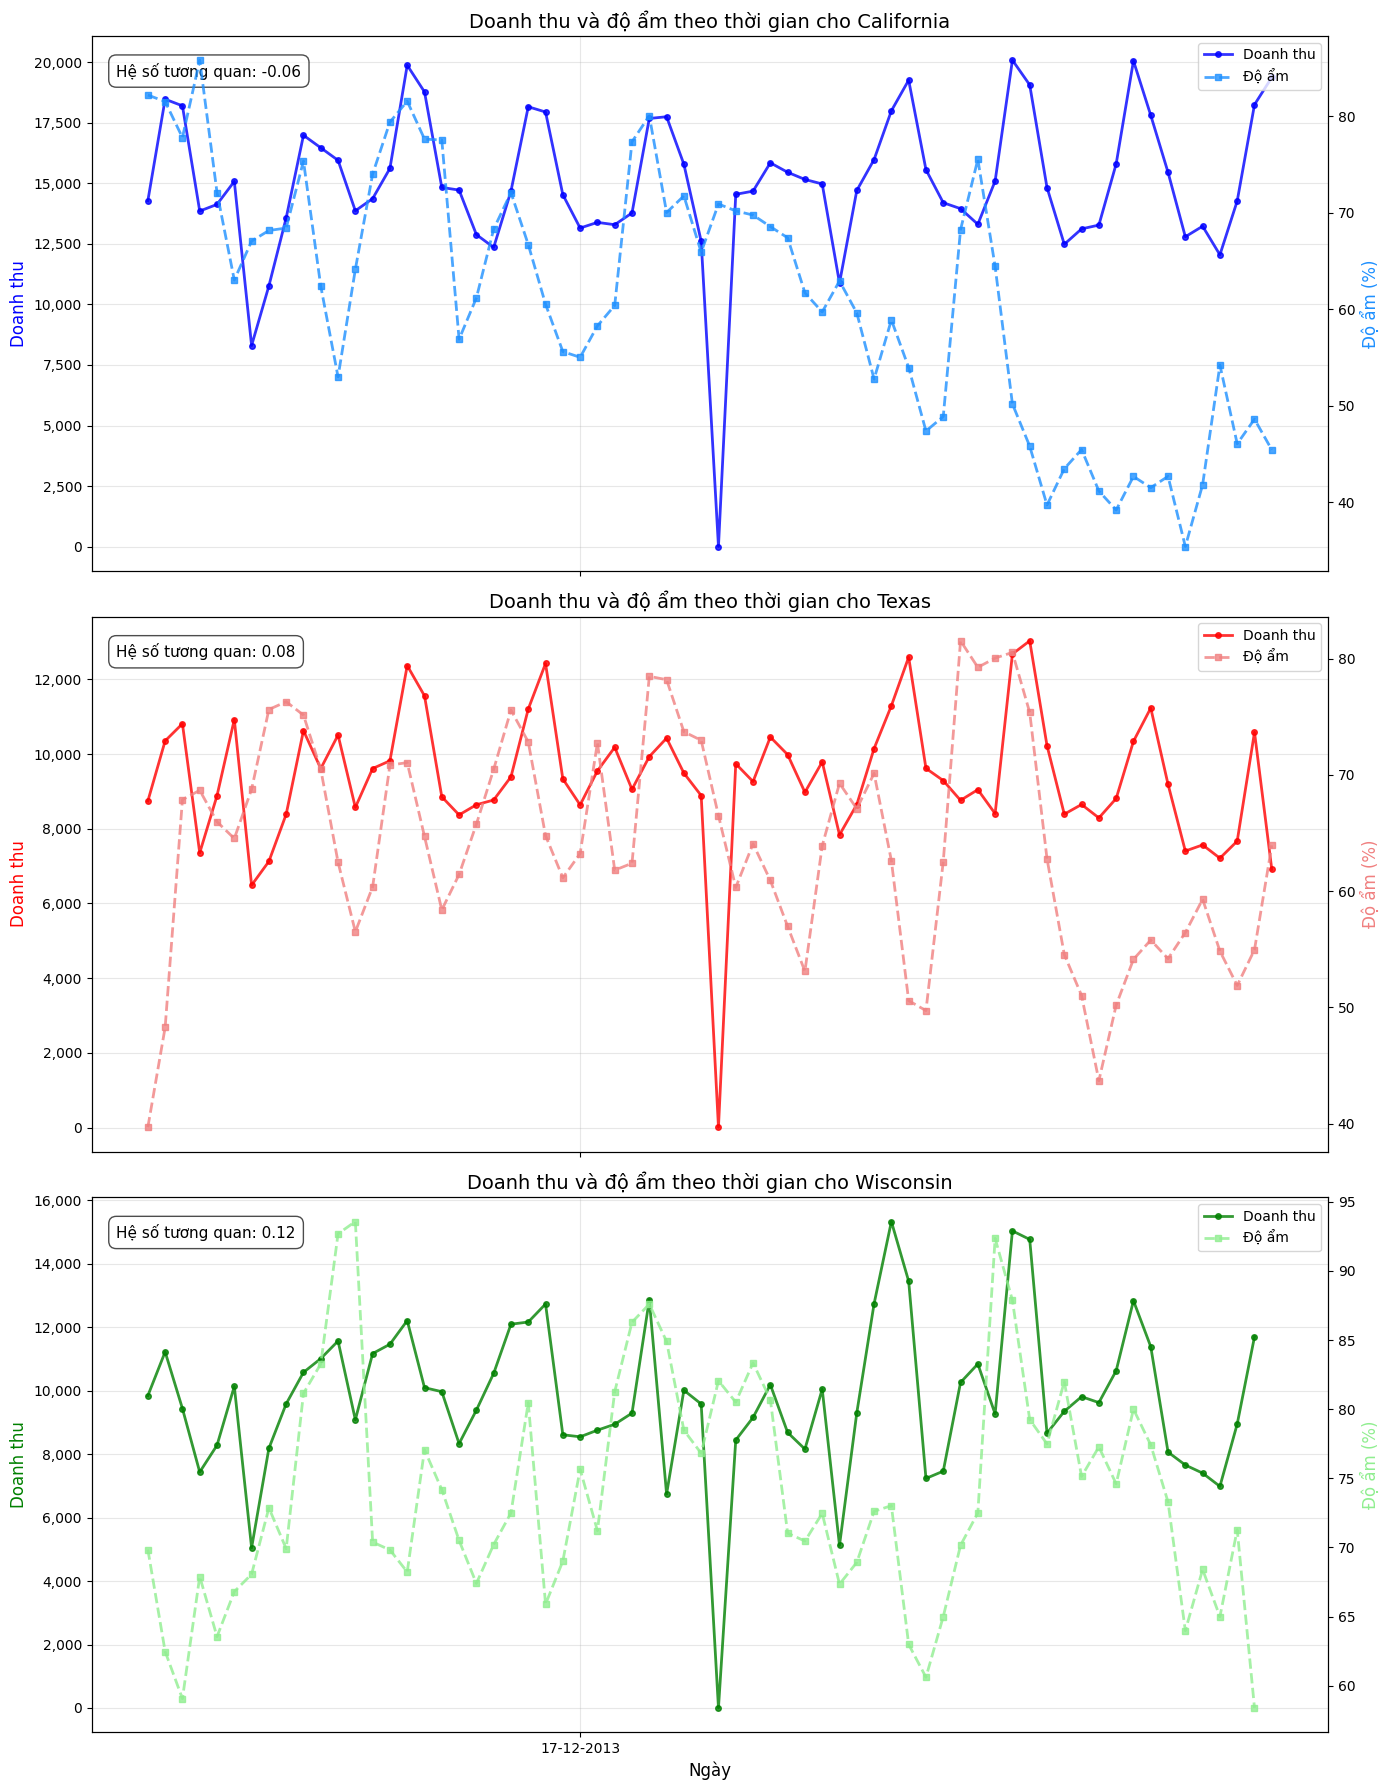

## Train bằng LGB và tìm kiếm các feature quan trọng

In [ ]:
df = pd.read_parquet('../../data/train_val.parquet')
df = df.drop(['date','disaster_type'],axis=1)

In [ ]:
sample_submission = pd.read_csv('../../data/sample_submission.csv')
sample_submission = downcast(sample_submission)

LAGS = [7, 28]
WINDOWS = [7, 28]
FIRST = 1942 # first to predict
LENGTH = 28

def demand_features_eval(df):
    """ Same as demand_features but for the step-by-step evaluation """
    out = df.groupby('id', sort=False).last()
    for lag in LAGS:
        out[f'lag_t{lag}'] = df.groupby('id', sort=False)['demand'].nth(-lag-1).astype("float32")
        for w in WINDOWS:
            out[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id', sort=False)['demand'].nth(list(range(-lag-w, -lag))).groupby('id', sort=False).mean().astype("float32")
    
    return out.reset_index()

def prep_train(df,drop_d = 1000):
    
    x = list(set(df.columns) - {'id', 'd', 'demand'})
    print(x)
    # Split into test, valid, train
    test = df[df.d >= FIRST - max(LAGS) - max(WINDOWS) - 28]
    df = df[df.d < FIRST]

    xtrain, xvalid, ytrain, yvalid = train_test_split(df[x], df["demand"], test_size=0.1, shuffle=True, random_state=54)
    train = lgb.Dataset(xtrain, label = ytrain)
    valid = lgb.Dataset(xvalid, label = yvalid)
    return train, valid, test, x

def fit_model(train, valid, num_r):
    """ Fit LightGBM model """
    
    params = {
        'metric': 'rmse',
        'objective': 'poisson',
        'seed': 200,
        'force_row_wise': True,
        'boosting_type': 'gbdt',
        'learning_rate': 0.015,
        'lambda': 0.1,
        'num_leaves': 63,
        'sub_row': 0.7,
        'bagging_freq': 1,
        'colsample_bytree': 0.7
    }

    callbacks = [
        early_stopping(stopping_rounds=200),
        log_evaluation(period=100)
    ]

    fit = lgb.train(params,
                    train,
                    num_boost_round=num_r,
                    valid_sets=[valid],
                    callbacks=callbacks)

    lgb.plot_importance(fit, importance_type="gain", precision=0, height=0.5, figsize=(6, 10))
    plt.show()

    return fit


def pred_all(fit, test, x):
    """ Calculate predictions """
    
    # Recursive prediction
    for i, day in enumerate(np.arange(FIRST, FIRST + LENGTH)):
        test_day = demand_features_eval(test[(test.d <= day) & (test.d >= day - max(LAGS) - max(WINDOWS))])
        test.loc[test.d == day, "demand"] = fit.predict(test_day[x])
    
    return test

def pred_to_csv(test, cols=sample_submission.columns, file="submission.csv"):
    """ Reshape predictions and save submission csv """
     
    # Prepare for reshaping
    test = test.assign(id=test.id + "_" + np.where(test.d < FIRST, "validation", "evaluation"),
                       F="F" + (test.d - FIRST + LENGTH + 1 - LENGTH * (test.d >= FIRST)).astype("str"))
    
    # Reshape
    submission = test.pivot(index="id", columns="F", values="demand").reset_index()[cols].fillna(1)
    
    # Export
    submission.to_csv(file, index=False)
    
    return True

train, valid, test, x = prep_train(df, 1000 - 28)

del df
gc.collect()

In [ ]:
def fit_model(train, valid, num_r):
    """ Fit LightGBM model """
    
    params = {
        'metric': 'rmse',
        'objective': 'poisson',
        'seed': 200,
        'force_row_wise': True,
        'boosting_type': 'gbdt',
        'learning_rate': 0.015,
        'lambda': 0.1,
        'num_leaves': 63,
        'sub_row': 0.7,
        'bagging_freq': 1,
        'colsample_bytree': 0.7
    }

    callbacks = [
        early_stopping(stopping_rounds=200),
        log_evaluation(period=100)
    ]

    fit = lgb.train(params,
                    train,
                    num_boost_round=num_r,
                    valid_sets=[valid],
                    callbacks=callbacks)

    lgb.plot_importance(fit, importance_type="gain", precision=0, height=0.5, figsize=(6, 10))
    plt.show()

    return fit


fit = fit_model(train, valid,200)
pred = pred_all(fit, test, x)
pred_to_csv(pred, cols=sample_submission.columns, file="../submission.csv")

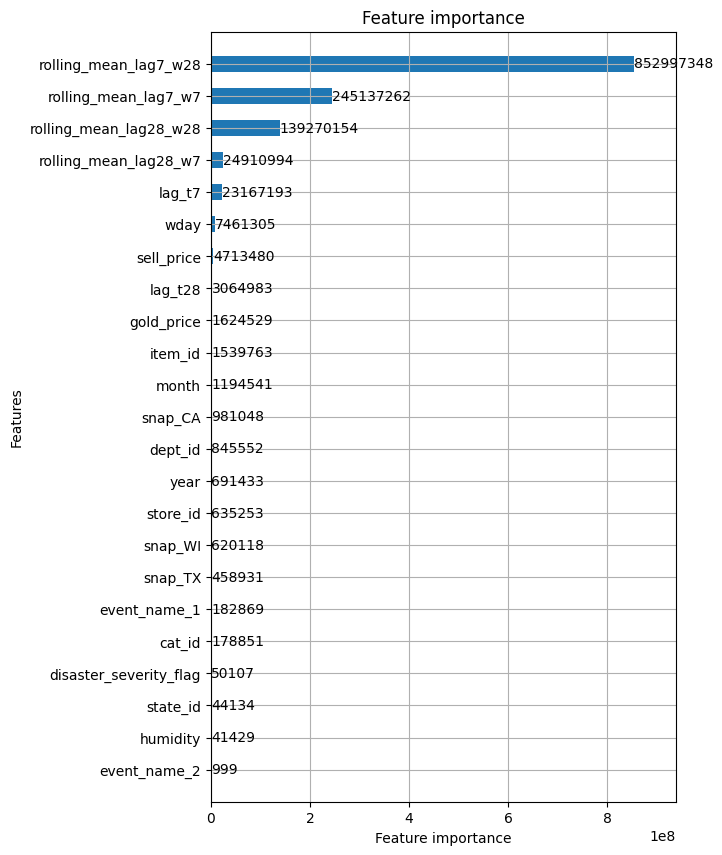

In [ ]:
# Lấy feature importances
importances = fit.feature_importance(importance_type='gain')

# Lấy tên feature từ dataset hoặc truyền vào nếu bạn có
feature_names = fit.feature_name()  # hoặc list tên feature tùy bạn cung cấp

# Tạo DataFrame
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

# Sắp xếp
importance_df = importance_df.sort_values('Importance', ascending=False)

# In ra
print("Feature importances (gain):")
print(importance_df[:10])

# Modeling and Evaluating 
Do có nhiều sự lựa chọn nên ở đây tụi em quyết định chọn LightGBM do có hiệu năng và cũng là model mạnh nhất hiện tại

Sau nhiều lần thử nghiệm với các model khác thì thấy LightGBM hiệu suất hơn hẳn

# Tối ưu trọng số bằng Bayesian optimization

  Để tối ưu trọng số, nhóm đã sử dụng tối ưu trọng số bằng thuật toán Tree-structured Parzen Estimator thuộc phương pháp bayesian optimization.


### 📌 TPE là gì?

TPE (Tree-structured Parzen Estimator) là một thuật toán tối ưu hóa Bayes, dùng để chọn ra các siêu tham số tốt nhất bằng cách mô hình hóa xác suất của tham số dựa trên kết quả trước đó. Thay vì tìm giá trị nào tối ưu hóa hàm mất mát, TPE ước lượng phân phối xác suất và lấy mẫu thông minh từ đó để tìm ra tổ hợp tốt hơn qua từng vòng lặp.

---

### 🔍 Nguyên lý hoạt động

TPE không xây dựng mô hình trực tiếp cho `objective function`, mà nó **mô hình hóa xác suất ngược**:

$$[
P(x | y) \quad \text{thay vì} \quad P(y | x)
]$$

TPE chia kết quả các trial thành hai nhóm:
- **Good trials**: Những bộ tham số có điểm số tốt nhất (ví dụ, loss thấp nhất).
- **Bad trials**: Phần còn lại.

Sau đó, TPE:
- Ước lượng hai phân phối xác suất: $$( l(x) )$$ và $$( g(x) )$$
  - $$( l(x) = P(x | y < y^*) )$$
  - $$( g(x) = P(x | y \geq y^*) )$$
- Chọn tham số mới $$( x )$$ sao cho **tỉ lệ** $$( \frac{l(x)}{g(x)} )$$ là **cao nhất**.

---

### 📈 Ưu điểm

- Khả năng học từ lịch sử trial để cải thiện dần dần.
- Tốt hơn random search đặc biệt trong không gian tham số liên tục hoặc rộng.
- Hỗ trợ các loại siêu tham số: `int`, `float`, `categorical`, `log-uniform`, v.v.

---


In [ ]:
null_columns = df.columns[df.isna().any()].tolist()

# Kiểm tra giá trị 0
zero_columns = df.columns[(df == 0).any()].tolist()

print("Các cột có giá trị null:", null_columns)
print("Các cột có giá trị 0:", zero_columns)

In [ ]:
df = df.drop(['date','disaster_type'],axis=1)
sample_submission = pd.read_csv('../../data/sample_submission.csv')
sample_submission = downcast(sample_submission)

LAGS = [7, 28]
WINDOWS = [7, 28]
FIRST = 1942 # first to predict
LENGTH = 28

def demand_features_eval(df):
    """ Same as demand_features but for the step-by-step evaluation """
    out = df.groupby('id', sort=False).last()
    for lag in LAGS:
        out[f'lag_t{lag}'] = df.groupby('id', sort=False)['demand'].nth(-lag-1).astype("float32")
        for w in WINDOWS:
            out[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id', sort=False)['demand'].nth(list(range(-lag-w, -lag))).groupby('id', sort=False).mean().astype("float32")
    
    return out.reset_index()

def prep_train(df,drop_d = 1000):

    x = list(set(df.columns) - {'id', 'd', 'demand'}) # exclude 'date' from features
    print(x)
    # Split into test, valid, train
    test = df[df.d >= FIRST - max(LAGS) - max(WINDOWS) - 28]
    df = df[df.d < FIRST]

    xtrain, xvalid, ytrain, yvalid = train_test_split(df[x], df["demand"], test_size=0.1, shuffle=True, random_state=54)
    train = lgb.Dataset(xtrain, label = ytrain)
    valid = lgb.Dataset(xvalid, label = yvalid)

    # return validation data for Optuna
    return train, valid, test, x, xvalid, yvalid



def pred_all(fit, test, x):
    """ Calculate predictions """
    
    # Recursive prediction
    for i, day in enumerate(np.arange(FIRST, FIRST + LENGTH)):
        test_day = demand_features_eval(test[(test.d <= day) & (test.d >= day - max(LAGS) - max(WINDOWS))])
        test.loc[test.d == day, "demand"] = fit.predict(test_day[x])
    
    return test

def pred_to_csv(test, cols=sample_submission.columns, file="submission.csv"):
    """ Reshape predictions and save submission csv """
     
    # Prepare for reshaping
    test = test.assign(id=test.id + "_" + np.where(test.d < FIRST, "validation", "evaluation"),
                       F="F" + (test.d - FIRST + LENGTH + 1 - LENGTH * (test.d >= FIRST)).astype("str"))
    
    # Reshape
    submission = test.pivot(index="id", columns="F", values="demand").reset_index()[cols].fillna(1)
    
    # Export
    submission.to_csv(file, index=False)
    
    return True

train, valid, test, x, X_valid, y_valid = prep_train(df, 1000 - 28)

del df
gc.collect()

## Train model với optuna để tìm tham số tối ưu
Kết quả của việc tối ưu tham số ở đây được đánh giá dựa vào kết quả submit được ở cuộc thi, với score WRMSSE là 0.58231 thì nhóm đã lên đứng được ở Top64 cuộc thi

![Screenshot 2025-05-05 222532.png](<attachment:Screenshot 2025-05-05 222532.png>)
![Screenshot 2025-05-05 222544.png](<attachment:Screenshot 2025-05-05 222544.png>)
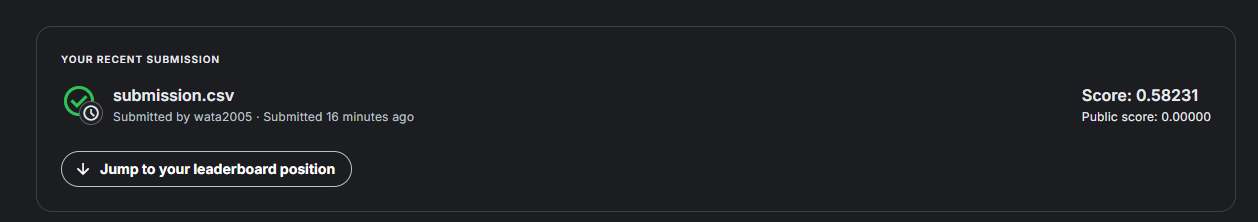
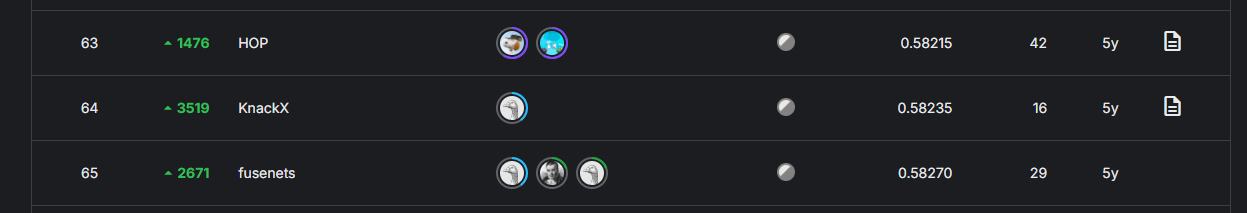

In [ ]:
def objective(trial):
    # Gợi ý các hyperparameter
    param = {
        'objective': 'regression',
        'metric': 'rmse',
        'verbosity': -1,
        'boosting_type': 'gbdt',
        'feature_pre_filter': False,
        'lambda_l1': trial.suggest_float('lambda_l1', 1e-8, 10.0, log=True),
        'learning_rate': trial.suggest_float('learning_rate', 1e-8, 10.0, log=True),
        'lambda_l2': trial.suggest_float('lambda_l2', 1e-8, 10.0, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 1000, 3000),
        'feature_fraction': trial.suggest_float('feature_fraction', 0.4, 1.0),
        'bagging_fraction': trial.suggest_float('bagging_fraction', 0.4, 1.0),
        'bagging_freq': trial.suggest_int('bagging_freq', 1, 7),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 100),
    }

    callbacks = [
        early_stopping(stopping_rounds=200),
        log_evaluation(period=100)
    ]

    # Train
    gbm = lgb.train(
        param,
        train,
        valid_sets=[valid],
        num_boost_round=600,    
        callbacks=callbacks,
    )

    preds = gbm.predict(X_valid)
    rmse = np.sqrt(mean_squared_error(y_valid, preds))

    return rmse  # Tối ưu RMSE → minimize

# Study
study = optuna.create_study(direction="minimize", pruner=optuna.pruners.MedianPruner())
study.optimize(objective, n_trials=30)

# Kết quả
print("Best trial:")
trial = study.best_trial
print(f"  RMSE: {trial.value}")
print("  Params: ")
for key, value in trial.params.items():
    print(f"    {key}: {value}")

In [7]:
df = pd.read_parquet('../../data/train_val.parquet')
print(df.head())

def downcast(df):
    cols = df.dtypes.index.tolist()
    types = df.dtypes.values.tolist()
    
    for i, t in enumerate(types):
        col = cols[i]
        if 'int' in str(t):
            c_min = df[col].min()
            c_max = df[col].max()
            if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                df[col] = df[col].astype(np.int8)
            elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                df[col] = df[col].astype(np.int16)
            elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                df[col] = df[col].astype(np.int32)
            else:
                df[col] = df[col].astype(np.int64)

        elif 'float' in str(t):
            c_min = df[col].min()
            c_max = df[col].max()
            # ⚠️ Không dùng float16 vì không lưu được trong Parquet
            if c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                df[col] = df[col].astype(np.float32)
            else:
                df[col] = df[col].astype(np.float64)    
    return df

df = downcast(df)
print(df.columns)


                   id  item_id  store_id  state_id  dept_id  cat_id     d  \
0  HOBBIES_1_001_CA_1     1438         1         1        4       2  1029   
1  HOBBIES_1_002_CA_1     1439         1         1        4       2  1029   
2  HOBBIES_1_003_CA_1     1440         1         1        4       2  1029   
3  HOBBIES_1_004_CA_1     1441         1         1        4       2  1029   
4  HOBBIES_1_005_CA_1     1442         1         1        4       2  1029   

   demand  lag_t7  rolling_mean_lag7_w7  ...  event_name_2  snap_CA  snap_TX  \
0     0.0     0.0              1.000000  ...             1        0        0   
1     0.0     1.0              0.142857  ...             1        0        0   
2     0.0     0.0              0.000000  ...             1        0        0   
3     3.0     0.0              1.142857  ...             1        0        0   
4     1.0     1.0              0.428571  ...             1        0        0   

   snap_WI sell_price  disaster_type  disaster_severity_

In [8]:
null_columns = df.columns[df.isna().any()].tolist()

# Kiểm tra giá trị 0
zero_columns = df.columns[(df == 0).any()].tolist()

print("Các cột có giá trị null:", null_columns)
print("Các cột có giá trị 0:", zero_columns)

Các cột có giá trị null: ['demand', 'lag_t7', 'rolling_mean_lag7_w7', 'rolling_mean_lag7_w28', 'sell_price', 'disaster_type']
Các cột có giá trị 0: ['demand', 'lag_t7', 'rolling_mean_lag7_w7', 'rolling_mean_lag7_w28', 'lag_t28', 'rolling_mean_lag28_w7', 'rolling_mean_lag28_w28', 'snap_CA', 'snap_TX', 'snap_WI', 'disaster_severity_flag', 'flag_ufc']


In [ ]:
df = df.drop(['date','disaster_type','disaster_severity_flag', 'flag_ufc', 'humidity'],axis=1)
sample_submission = pd.read_csv('../../data/sample_submission.csv')
sample_submission = downcast(sample_submission)

LAGS = [7, 28]
WINDOWS = [7, 28]
FIRST = 1942 # first to predict
LENGTH = 28

def demand_features_eval(df):
    """ Same as demand_features but for the step-by-step evaluation """
    out = df.groupby('id', sort=False).last()
    for lag in LAGS:
        out[f'lag_t{lag}'] = df.groupby('id', sort=False)['demand'].nth(-lag-1).astype("float32")
        for w in WINDOWS:
            out[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id', sort=False)['demand'].nth(list(range(-lag-w, -lag))).groupby('id', sort=False).mean().astype("float32")
    
    return out.reset_index()

def prep_train(df,drop_d = 1000):
    
    x = list(set(df.columns) - {'id', 'd', 'demand'})
    print(x)
    # Split into test, valid, train
    test = df[df.d >= FIRST - max(LAGS) - max(WINDOWS) - 28]
    df = df[df.d < FIRST]

    xtrain, xvalid, ytrain, yvalid = train_test_split(df[x], df["demand"], test_size=0.1, shuffle=True, random_state=54)
    train = lgb.Dataset(xtrain, label = ytrain)
    valid = lgb.Dataset(xvalid, label = yvalid)
    return train, valid, test, x

def fit_model(train, valid, num_r):
    """ Fit LightGBM model """
    
    params = {
        'metric': 'rmse',
        'objective': 'poisson',
        'seed': 200,
        'force_row_wise': True,
        'learning_rate': 0.047586309425667044,
        'lambda_l1': 0.03868486588558565,
        'lambda_l2': 8.320083593072901,
        'num_leaves': 2821,
        'feature_fraction': 0.9657558945465752,
        'bagging_fraction': 0.7792310380094438,
        'bagging_freq': 1,
        'min_child_samples': 7,
    }

    callbacks = [
        early_stopping(stopping_rounds=200),
        log_evaluation(period=100)
    ]

    fit = lgb.train(params,
                    train,
                    num_boost_round=num_r,
                    valid_sets=[valid],
                    callbacks=callbacks)

    lgb.plot_importance(fit, importance_type="gain", precision=0, height=0.5, figsize=(6, 10))
    plt.show()

    return fit


def pred_all(fit, test, x):
    """ Calculate predictions """
    
    # Recursive prediction
    for i, day in enumerate(np.arange(FIRST, FIRST + LENGTH)):
        test_day = demand_features_eval(test[(test.d <= day) & (test.d >= day - max(LAGS) - max(WINDOWS))])
        test.loc[test.d == day, "demand"] = fit.predict(test_day[x])
    
    return test

def pred_to_csv(test, cols=sample_submission.columns, file="submission.csv"):
    """ Reshape predictions and save submission csv """
     
    # Prepare for reshaping
    test = test.assign(id=test.id + "_" + np.where(test.d < FIRST, "validation", "evaluation"),
                       F="F" + (test.d - FIRST + LENGTH + 1 - LENGTH * (test.d >= FIRST)).astype("str"))
    
    # Reshape
    submission = test.pivot(index="id", columns="F", values="demand").reset_index()[cols].fillna(1)
    
    # Export
    submission.to_csv(file, index=False)
    
    return True

train, valid, test, x = prep_train(df, 1000 - 28)

del df
gc.collect()

['item_id', 'rolling_mean_lag7_w28', 'event_name_2', 'snap_TX', 'dept_id', 'store_id', 'wday', 'snap_WI', 'snap_CA', 'state_id', 'rolling_mean_lag28_w28', 'cat_id', 'month', 'rolling_mean_lag28_w7', 'year', 'event_name_1', 'sell_price', 'lag_t7', 'lag_t28', 'rolling_mean_lag7_w7', 'gold_price']


172

[LightGBM] [Warning] feature_fraction is set=0.9657558945465752, colsample_bytree=0.7 will be ignored. Current value: feature_fraction=0.9657558945465752
[LightGBM] [Warning] bagging_fraction is set=0.7792310380094438, sub_row=0.7 will be ignored. Current value: bagging_fraction=0.7792310380094438
[LightGBM] [Warning] feature_fraction is set=0.9657558945465752, colsample_bytree=0.7 will be ignored. Current value: feature_fraction=0.9657558945465752
[LightGBM] [Warning] bagging_fraction is set=0.7792310380094438, sub_row=0.7 will be ignored. Current value: bagging_fraction=0.7792310380094438
[LightGBM] [Info] Total Bins 2034
[LightGBM] [Info] Number of data points in the train set: 25053633, number of used features: 21
[LightGBM] [Warning] feature_fraction is set=0.9657558945465752, colsample_bytree=0.7 will be ignored. Current value: feature_fraction=0.9657558945465752
[LightGBM] [Warning] bagging_fraction is set=0.7792310380094438, sub_row=0.7 will be ignored. Current value: bagging_f

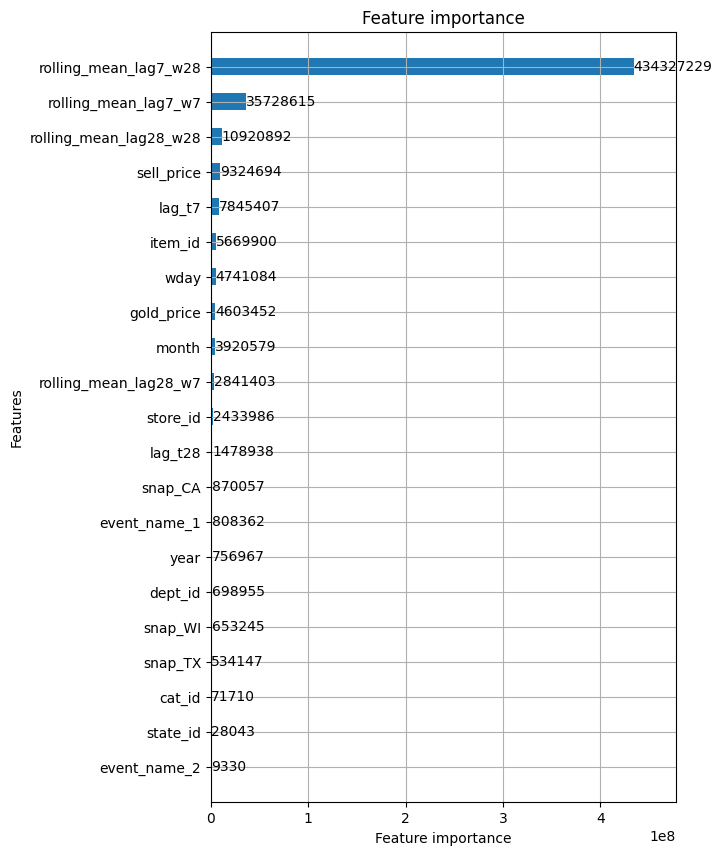

True

In [10]:
fit = fit_model(train, valid,200)
pred = pred_all(fit, test, x)
pred_to_csv(pred, cols=sample_submission.columns, file="../submission.csv")